# 04 · Comparativa final

No entrena nada: lee los resultados que guardaron 00–03 en `results/` y construye la comparación final, las figuras y la tabla del informe.

| § | Contenido | Fuentes |
|---|---|---|
| 1 | Tabla comparativa final: rendimiento y convergencia en los 4 mercados del taller | `00_baselines`, `01_qlearning`, `02_sarsa` |
| 2 | ¿Es la estrategia esperada? | 00–02 |
| 3 | Q-Learning frente a SARSA: hiperparámetros, convergencia y estabilidad | `01_*`, `02_*`, `02_duelo` |
| 4 | Más allá de los mínimos: estado enriquecido, mercados extra, S&P 500 y robustez | `03_*` |
| 5 | Figuras y tabla para el informe | todos |
| 6 | Análisis crítico | todos |

Todas las cifras proceden de los CSV; reabrir este notebook no reentrena ningún agente. Las salidas son `results/04_*.csv` / `.md` y las figuras `results/figures/04_*.png`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.experiment import RESULT_COLUMNS, RESULTS_DIR
from src.style import setup, savefig, AGENT_COLORS, MARKET_COLORS, MARKET_LABELS

setup()
pd.set_option("display.precision", 4)
MARKETS_4 = ["tendencia_ciclo", "browniano", "reversion_media", "regimenes"]


def load(name):
    """Lee `results/<name>.csv`. El 04 no entrena: solo lee lo que guardaron 00–03."""
    return pd.read_csv(RESULTS_DIR / f"{name}.csv")


## 1. Tabla comparativa final

Los cuatro mercados del taller × los cuatro agentes, en las **200 series de test** (D-0.1). Los baselines salen de
`00_baselines.csv`; Q-Learning y SARSA, de `01_qlearning.csv` y `02_sarsa.csv`: cada fila es la mediana de 5 semillas,
con los hiperparámetros elegidos en validación (D-0.4, D-2.3). Aquí no se entrena nada.

- **Métrica principal: la mediana del retorno** (D-0.3). En tendencia + ciclo la media es enorme y muy dispersa, así
  que ese mercado se expresa como múltiplo del capital (x = 1 + retorno).
- **Convergencia:** episodio en que la media móvil de la recompensa de entrenamiento alcanza el 90 % de su mejora
  (D-0.3). Si el agente no opera, se deja en blanco: su curva sube solo porque ε baja (01 §6).
- En negrita, el agente con mayor mediana en cada mercado (los empates, todos).

In [2]:
TF_AGENTS = ["aleatorio", "buy_hold", "qlearning", "sarsa"]
TF_AGENT_NAMES = {"aleatorio": "Aleatorio", "buy_hold": "Buy & hold", "qlearning": "Q-Learning", "sarsa": "SARSA"}

tf_long = pd.concat([load("00_baselines"), load("01_qlearning"), load("02_sarsa")], ignore_index=True)[RESULT_COLUMNS]
tf_long = tf_long[tf_long.mercado.isin(MARKETS_4)].copy()
tf_long["mercado"] = pd.Categorical(tf_long.mercado, MARKETS_4, ordered=True)
tf_long["agente"] = pd.Categorical(tf_long.agente, TF_AGENTS, ordered=True)
tf_long = tf_long.sort_values(["mercado", "agente"]).reset_index(drop=True)
assert len(tf_long) == 16 and not tf_long.duplicated(["mercado", "agente"]).any()

# Convergencia solo donde hay una estrategia que aprender (01 §6); los baselines no entrenan
tf_long.loc[tf_long.n_trades == 0, "episodios_convergencia"] = np.nan
tf_long.loc[tf_long.agente.isin(["aleatorio", "buy_hold"]), "tiempo_s"] = np.nan

# Ganador por mercado: mayor mediana (empates dentro de 1e-9)
best = tf_long.groupby("mercado", observed=True).retorno_mediana.transform("max")
tf_long["gana"] = (tf_long.retorno_mediana >= best - 1e-9)
tf_long.astype({"mercado": str, "agente": str}).to_csv(RESULTS_DIR / "04_tabla_final.csv", index=False)

def tf_ret(v, m):
    if m == "tendencia_ciclo":                                   # múltiplo del capital, x = 1 + retorno
        return f"x{1 + v:.1f}" if 1 + v < 100 else f"x{1 + v:,.0f}"
    return f"{v:+.1%}"

def tf_es(v, m):
    """Igual que tf_ret, con formato español para el texto (coma decimal, espacio de miles, signo −)."""
    if m == "tendencia_ciclo":
        return tf_ret(v, m).replace(",", " ").replace(".", ",")
    return "0 %" if abs(v) < 1e-12 else f"{100 * v:+.1f} %".replace(".", ",").replace("-", "−")

def tf_mean_std(mu, sd, m):
    return f"x{1 + mu:,.0f} ± {sd:,.0f}" if m == "tendencia_ciclo" else f"{mu:+.1%} ± {sd:.1%}"

tf_show = pd.DataFrame({
    "Mercado": [MARKET_LABELS[m] for m in tf_long.mercado],
    "Agente": [TF_AGENT_NAMES[a] for a in tf_long.agente],
    "Retorno mediano": [tf_ret(v, m) for v, m in zip(tf_long.retorno_mediana, tf_long.mercado)],
    "Media ± std": [tf_mean_std(a, b, m) for a, b, m in zip(tf_long.retorno_medio, tf_long["std"], tf_long.mercado)],
    "Sharpe (por paso)": tf_long.sharpe.map("{:.3f}".format),
    "Caída máx.": tf_long.max_drawdown.map("{:.0%}".format),
    "Ops/episodio": tf_long.n_trades.map("{:.0f}".format),
    "Convergencia (ep.)": tf_long.episodios_convergencia.map(lambda v: "—" if pd.isna(v) else f"{v:.0f}"),
    "Tiempo (s)": tf_long.tiempo_s.map(lambda v: "—" if pd.isna(v) else f"{v:.0f}"),
}).set_index(["Mercado", "Agente"])
tf_bold = tf_long.gana.to_numpy()
display(tf_show.style
        .apply(lambda col: ["font-weight:bold; background-color:#EAF4FB" if g else "" for g in tf_bold], axis=0)
        .set_caption("Test, 200 series · Q-Learning y SARSA: mediana de 5 semillas · guardada en results/04_tabla_final.csv"))

In [3]:
tf_piv = tf_long.pivot(index="mercado", columns="agente", values="retorno_mediana").reindex(MARKETS_4)
filas = []
for m in MARKETS_4:
    g = tf_long[(tf_long.mercado == m) & tf_long.gana]
    quien = " = ".join(TF_AGENT_NAMES[a] for a in g.agente.astype(str))
    rl = max(tf_piv.loc[m, "qlearning"], tf_piv.loc[m, "sarsa"])
    margen = (f"x{(1 + rl) / (1 + tf_piv.loc[m, 'buy_hold']):.1f} su capital final" if m == "tendencia_ciclo"
              else f"{100 * (rl - tf_piv.loc[m, 'buy_hold']):+.1f} puntos")
    margen = margen.replace(".", ",")
    opera = "no opera" if g.n_trades.max() == 0 else f"{g.n_trades.median():.0f} ops/ep."
    filas.append(f"| {MARKET_LABELS[m]} | **{quien}** ({tf_es(g.retorno_mediana.iloc[0], m)}, {opera}) | {margen} |")
display(Markdown("| Mercado | Gana | Mejor agente RL frente a buy & hold |\n|---|---|---|\n" + "\n".join(filas)))

tf_q = tf_long.set_index(["agente", "mercado"]).loc["qlearning"]
tf_s = tf_long.set_index(["agente", "mercado"]).loc["sarsa"]
tf_duelo = load("02_duelo").groupby(["mercado", "agente"])[["episodios_convergencia", "tiempo_s"]].median()
t = "tendencia_ciclo"
std_t = f"{tf_q.loc[t, 'std']:,.0f}".replace(",", " ")
seg = lambda v: f"{v:.1f}".replace(".", ",")
conv = lambda m, a: f"{tf_duelo.loc[(m, a), 'episodios_convergencia']:.0f}"
display(Markdown(
    f"- **Mediana frente a media.** En tendencia + ciclo la media de Q-Learning es {tf_es(tf_q.loc[t, 'retorno_medio'], t)} "
    f"(std {std_t}) y la mediana {tf_es(tf_q.loc[t, 'retorno_mediana'], t)}: unas pocas series explosivas tiran de la "
    f"media, por eso se compara con la mediana (D-0.3).\n"
    f"- **La convergencia de esta tabla no compara algoritmos**, porque cada uno tiene sus hiperparámetros: en reversión sale "
    f"Q-Learning {tf_q.loc['reversion_media', 'episodios_convergencia']:.0f} y SARSA "
    f"{tf_s.loc['reversion_media', 'episodios_convergencia']:.0f}, pero Q-Learning usa γ = 0,5. Con la misma configuración "
    f"(duelo, 02 §9) Q-Learning converge antes: {conv(t, 'qlearning')} frente a {conv(t, 'sarsa')} episodios en el mercado 1 "
    f"y {conv('reversion_media', 'qlearning')} frente a {conv('reversion_media', 'sarsa')} en reversión (D-2.5).\n"
    f"- **El tiempo tampoco es comparable entre el 01 y el 02**: se ejecutaron en máquinas distintas (02 §10). En el duelo, "
    f"en la misma máquina y con 1 000 episodios, los dos tardan lo mismo en el mercado 1 "
    f"({seg(tf_duelo.loc[(t, 'qlearning'), 'tiempo_s'])} s y {seg(tf_duelo.loc[(t, 'sarsa'), 'tiempo_s'])} s)."))

| Mercado | Gana | Mejor agente RL frente a buy & hold |
|---|---|---|
| 1 · Tendencia + ciclo | **Q-Learning** (x502, 48 ops/ep.) | x14,9 su capital final |
| 2 · Browniano geométrico | **Q-Learning = SARSA** (0 %, no opera) | +3,5 puntos |
| 3 · Reversión a la media | **Q-Learning = SARSA** (+27,0 %, 29 ops/ep.) | +27,3 puntos |
| 4 · Regímenes | **Q-Learning = SARSA** (0 %, no opera) | +12,5 puntos |

- **Mediana frente a media.** En tendencia + ciclo la media de Q-Learning es x1 987 (std 3 903) y la mediana x502: unas pocas series explosivas tiran de la media, por eso se compara con la mediana (D-0.3).
- **La convergencia de esta tabla no compara algoritmos**, porque cada uno tiene sus hiperparámetros: en reversión sale Q-Learning 350 y SARSA 292, pero Q-Learning usa γ = 0,5. Con la misma configuración (duelo, 02 §9) Q-Learning converge antes: 189 frente a 203 episodios en el mercado 1 y 260 frente a 282 en reversión (D-2.5).
- **El tiempo tampoco es comparable entre el 01 y el 02**: se ejecutaron en máquinas distintas (02 §10). En el duelo, en la misma máquina y con 1 000 episodios, los dos tardan lo mismo en el mercado 1 (18,9 s y 18,8 s).

## 2. ¿Es la estrategia esperada?

Para cada generador, la estrategia que cabía esperar (00 §2), lo que aprenden los dos agentes (mapas de política de
01 §8 y 02 §8) y si coincide. Las cifras son las de la tabla del §1.

In [4]:
sem04 = pd.concat([load("01_qlearning_semillas"), load("02_sarsa_semillas")], ignore_index=True)
def tf_cifras(m):
    p = tf_piv.loc[m]
    return f"Q-L {tf_es(p.qlearning, m)} · SARSA {tf_es(p.sarsa, m)} · B&H {tf_es(p.buy_hold, m)}"
ops = tf_long.set_index(["mercado", "agente"]).n_trades
esperada = [
    ("tendencia_ciclo", "Seguir la tendencia: dentro casi siempre (deriva) y fuera en la fase baja del ciclo",
     f"Entra con tendencia alta (bins 7–10 en Q-L, 6–10 en SARSA) y sale en los bajos (1–3); en medio no cambia de "
     f"posición (banda que ahorra comisiones). {ops[('tendencia_ciclo', 'qlearning')]:.0f} y {ops[('tendencia_ciclo', 'sarsa')]:.0f} ops/ep.",
     "✅ Sí", "01 §8, 02 §8"),
    ("browniano", "No operar: la tendencia no predice nada y operar solo paga comisiones",
     "No entra nunca (0 ops/ep.)", "✅ Sí", "01 §8, 02 §8"),
    ("reversion_media", "Comprar tras las caídas y vender tras las subidas",
     f"Compra solo tras la caída más fuerte (bin 1) y vende solo tras la subida más fuerte (bin 10); "
     f"{ops[('reversion_media', 'qlearning')]:.0f} ops/ep.", "✅ Sí", "01 §8, 02 §8"),
    ("regimenes", "A priori, seguir la tendencia (00 §2). Con este estado, no operar: ninguna de 70 reglas simples "
     "sobre el bin de tendencia bate al 0 % en validación",
     "No entra nunca (0 ops/ep.)", "✅ Sí, tras revisar la hipótesis (D-2.4)", "01 §9, D-2.4"),
]
display(Markdown(
    "| Mercado | Estrategia esperada | Qué aprenden Q-Learning y SARSA | Mediana en test | ¿Esperada? | Fuente |\n"
    "|---|---|---|---|---|---|\n" +
    "\n".join(f"| {MARKET_LABELS[m]} | {e} | {a} | {tf_cifras(m)} | {ok} | {src_} |" for m, e, a, ok, src_ in esperada)))

# Las dos tablas Q llegan a las mismas políticas: valores de test distintos que aparecen entre las 10 semillas
for m in ["tendencia_ciclo", "reversion_media"]:
    d = sem04[sem04.mercado == m]
    vals = sorted(d.retorno_mediana.round(6).unique())
    reparto = {TF_AGENT_NAMES[a]: ", ".join(tf_es(v, m) for v in g.sort_values().to_numpy())
               for a, g in d.groupby("agente").retorno_mediana}
    print(f"{MARKET_LABELS[m]}: {len(vals)} resultados distintos en 10 semillas · " +
          " | ".join(f"{k}: {v}" for k, v in reparto.items()))

| Mercado | Estrategia esperada | Qué aprenden Q-Learning y SARSA | Mediana en test | ¿Esperada? | Fuente |
|---|---|---|---|---|---|
| 1 · Tendencia + ciclo | Seguir la tendencia: dentro casi siempre (deriva) y fuera en la fase baja del ciclo | Entra con tendencia alta (bins 7–10 en Q-L, 6–10 en SARSA) y sale en los bajos (1–3); en medio no cambia de posición (banda que ahorra comisiones). 48 y 57 ops/ep. | Q-L x502 · SARSA x472 · B&H x33,6 | ✅ Sí | 01 §8, 02 §8 |
| 2 · Browniano geométrico | No operar: la tendencia no predice nada y operar solo paga comisiones | No entra nunca (0 ops/ep.) | Q-L 0 % · SARSA 0 % · B&H −3,5 % | ✅ Sí | 01 §8, 02 §8 |
| 3 · Reversión a la media | Comprar tras las caídas y vender tras las subidas | Compra solo tras la caída más fuerte (bin 1) y vende solo tras la subida más fuerte (bin 10); 29 ops/ep. | Q-L +27,0 % · SARSA +27,0 % · B&H −0,3 % | ✅ Sí | 01 §8, 02 §8 |
| 4 · Regímenes | A priori, seguir la tendencia (00 §2). Con este estado, no operar: ninguna de 70 reglas simples sobre el bin de tendencia bate al 0 % en validación | No entra nunca (0 ops/ep.) | Q-L 0 % · SARSA 0 % · B&H −12,5 % | ✅ Sí, tras revisar la hipótesis (D-2.4) | 01 §9, D-2.4 |

1 · Tendencia + ciclo: 3 resultados distintos en 10 semillas · Q-Learning: x472, x502, x502, x605, x605 | SARSA: x472, x472, x472, x502, x502
3 · Reversión a la media: 4 resultados distintos en 10 semillas · Q-Learning: +22,5 %, +27,0 %, +27,0 %, +27,0 %, +27,0 % | SARSA: +15,8 %, +21,6 %, +27,0 %, +27,0 %, +27,0 %


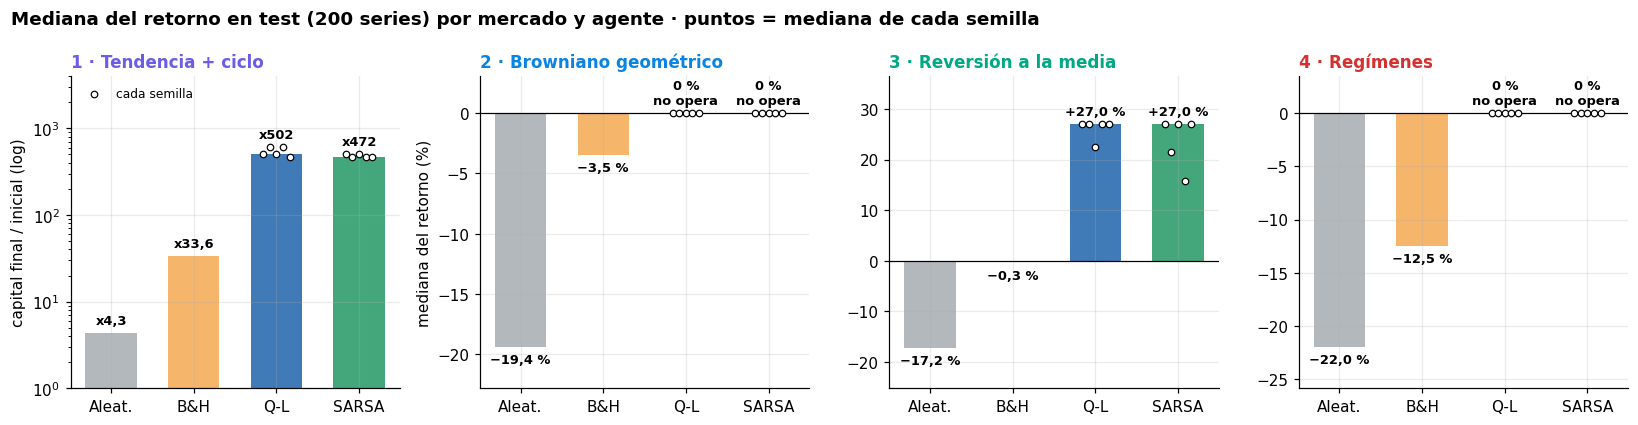

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax, m in zip(axes, MARKETS_4):
    t1 = m == "tendencia_ciclo"
    tr = (lambda v: 1 + v) if t1 else (lambda v: 100 * v)        # mercado 1: múltiplo del capital; resto: %
    for x, a in enumerate(TF_AGENTS):
        v = tf_piv.loc[m, a]
        ax.bar(x, tr(v), color=AGENT_COLORS[a], width=0.62, alpha=0.9 if a in ("qlearning", "sarsa") else 0.75)
        lab = tf_es(v, m)
        if a in ("qlearning", "sarsa") and abs(v) < 1e-12:
            lab = "0 %\nno opera"
        y_lab = tr(v)
        if t1 and a in ("qlearning", "sarsa"):                    # por encima de los puntos de las semillas
            y_lab = tr(sem04[(sem04.mercado == m) & (sem04.agente == a)].retorno_mediana.max())
        ax.annotate(lab, (x, y_lab), xytext=(0, 4 if (t1 or v >= 0) else -4), textcoords="offset points",
                    ha="center", va="bottom" if (t1 or v >= 0) else "top", fontsize=8.5, weight="bold")
        if a in ("qlearning", "sarsa"):
            sv = sem04[(sem04.mercado == m) & (sem04.agente == a)].retorno_mediana.to_numpy()
            ax.scatter(x + np.linspace(-0.16, 0.16, len(sv)), tr(sv), s=18, color="white", edgecolor="black",
                       lw=0.8, zorder=5, label="cada semilla" if (x == 2 and t1) else None)
    if t1:
        ax.set_yscale("log"); ax.set_ylabel("capital final / inicial (log)")
        ax.set_ylim(1, 4000)
    else:
        ax.axhline(0, color="black", lw=0.8)
        lo, hi = ax.get_ylim(); ax.set_ylim(lo - 0.12 * (hi - lo), hi + 0.15 * (hi - lo))
    ax.set_xticks(range(4), ["Aleat.", "B&H", "Q-L", "SARSA"])
    ax.set_title(MARKET_LABELS[m], loc="left", color=MARKET_COLORS[m])
axes[1].set_ylabel("mediana del retorno (%)")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Mediana del retorno en test (200 series) por mercado y agente · puntos = mediana de cada semilla",
             x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "04_minimos_retorno_mercado"); plt.show()

**Lectura.**

- **La estrategia es la esperada en los cuatro mercados**, y los dos algoritmos aprenden **la misma**. En el mercado 1
  sigue la tendencia y multiplica por ≈ 15 el capital final de buy & hold; en reversión compra en el extremo bajista y
  vende en el alcista (+27,3 puntos sobre buy & hold). En el browniano y en regímenes se queda fuera.
- **No operar no es lo mismo en el browniano que en regímenes.** En el browniano no hay nada que aprender, y su 0 %
  "gana" a buy & hold por prudencia, no por habilidad (01 §8). En regímenes sí hay estructura, pero la tendencia de 6
  precios llega tarde y no identifica el régimen: el límite es el estado, no el algoritmo (01 §9, D-2.4). Con
  volatilidad y distancia a MA30 en el estado, Q-Learning pasa a +7,8 % (03 §6).
- **La diferencia entre Q-Learning y SARSA en el mercado 1 no es de estrategia.** Las 10 semillas dan solo tres
  resultados distintos (salida anterior): x472 y x502 aparecen con los dos algoritmos y x605 solo en dos semillas de
  Q-Learning. La mediana depende de cuántas semillas caen en cada política, y por eso sale x502 frente a x472. Con
  20 estados × 3 acciones hay pocas políticas greedy posibles (02 §7). En reversión la mediana coincide (+27,0 %), pero
  SARSA tiene peores semillas (+15,8 % frente a +22,5 %), coherente con su objetivo más ruidoso (02 §10).

## 3. Q-Learning frente a SARSA

Las dos líneas de trabajo (01 y 02) usaron **el mismo protocolo**: mismo punto de partida, mismas rejillas, 100 series de
validación, 3 semillas por configuración y regla de parsimonia (D-0.4, D-2.3). Aquí se ponen lado a lado para responder
tres preguntas:

| § | Pregunta | Fuente |
|---|---|---|
| 3.1 | ¿Con qué hiperparámetros acaba cada algoritmo? | `01_grid_*.csv`, `02_grid_*.csv`, `*_semillas.csv` |
| 3.2 | ¿Cuál converge antes? | `02_duelo.csv` (misma configuración, mismas semillas; D-2.5) |
| 3.3 | ¿Cuál es más estable entre semillas? | `01_qlearning_semillas.csv`, `02_sarsa_semillas.csv` (test) |
| 3.4 | ¿Por qué llegan a la misma política y cuándo difieren? | 02 §5, §7 y §9 |

### 3.1 Hiperparámetros elegidos

Se ajusta **por mercado y por etapas** (α → γ → ε → episodios). Cada configuración se puntúa con la mediana, entre 3
semillas, de la mediana del retorno en validación. Un valor nuevo solo sustituye al de partida (α 0,001, γ 0,9,
ε 0,99 / 0,01, 500 episodios) si le gana en la mayoría de las semillas. La tabla recoge la configuración final de cada
algoritmo y su puntuación en validación.

In [6]:
def fmt_ret_alg(v, m):
    """Mismo formato que 01–02: multiplicador (1 + r) en el mercado 1 y porcentaje en el resto."""
    return f"x{1 + v:,.0f}" if m == "tendencia_ciclo" else f"{v:+.1%}"

ALG = {"qlearning": "Q-Learning", "sarsa": "SARSA"}
HP = ["alpha", "gamma", "epsilon_decay", "epsilon_min", "n_episodes"]
alg_sem = pd.concat([load("01_qlearning_semillas"), load("02_sarsa_semillas")], ignore_index=True)
assert (alg_sem.groupby(["agente", "mercado"])[HP].nunique() == 1).all().all()   # una configuración por mercado
alg_cfg = alg_sem.groupby(["agente", "mercado"])[HP].first()

# Puntuación en validación de la configuración elegida (última etapa del ajuste: episodios).
alg_grid_n = {"qlearning": load("01_grid_episodios"), "sarsa": load("02_grid_episodios")}
def alg_score_val(agente, mercado):
    g, c = alg_grid_n[agente], alg_cfg.loc[(agente, mercado)]
    sel = (g.mercado == mercado) & np.logical_and.reduce([np.isclose(g[k], c[k]) for k in HP])
    assert sel.sum() == 3
    return g[sel].retorno_mediana.median()
alg_cfg["val"] = [alg_score_val(a, m) for a, m in alg_cfg.index]

def alg_num(v):
    return f"{v:g}".replace(".", ",")
filas = {}
for m in MARKETS_4:
    q, s = alg_cfg.loc[("qlearning", m)], alg_cfg.loc[("sarsa", m)]
    par = lambda f: {"Q-Learning": f(q), "SARSA": f(s)}
    filas[MARKET_LABELS[m]] = {
        **{("α", k): v for k, v in par(lambda r: alg_num(r.alpha)).items()},
        **{("γ", k): v for k, v in par(lambda r: alg_num(r.gamma)).items()},
        **{("ε decaimiento / mínimo", k): v for k, v in par(lambda r: f"{alg_num(r.epsilon_decay)} / {alg_num(r.epsilon_min)}").items()},
        **{("Episodios", k): v for k, v in par(lambda r: f"{int(r.n_episodes):,}".replace(",", ".")).items()},
        **{("Validación", k): v for k, v in par(lambda r: fmt_ret_alg(r.val, m)).items()},
    }
tabla_hp = pd.DataFrame(filas).T
tabla_hp.columns = pd.MultiIndex.from_tuples(tabla_hp.columns)

def alg_marca_distinto(col):
    """Resalta los hiperparámetros en que los dos algoritmos difieren."""
    otro = tabla_hp[(col.name[0], "SARSA" if col.name[1] == "Q-Learning" else "Q-Learning")]
    return ["font-weight:bold;background-color:#FFF4E0" if a != b else "" for a, b in zip(col, otro)]

display(tabla_hp.style.apply(alg_marca_distinto, subset=[c for c in tabla_hp.columns if c[0] != "Validación"])
        .set_caption("Hiperparámetros finales por mercado (resaltado: donde difieren) · validación: mediana de 3 semillas, 100 series"))

**Lectura.**

- **α pequeño en los dos.** Para Q-Learning, α es una **meseta** entre 0,0005 y 0,01 (mercado 1: x518 – x527 en
  validación) y se queda en 0,001. SARSA prefiere 0,0005 en los mercados 1 y 3, coherente con un objetivo más ruidoso
  porque usa la acción muestreada (02 §3). Con α = 0,1 los dos se hunden en el mercado 1 (x14 y x19; D-2.2).
- **γ = 0 en el mercado 1 para los dos** (el agente miope gana: con un 10 % de ruido por paso, el futuro lejano se estima
  mal; 01 §4). En reversión, Q-Learning elige 0,5 y SARSA mantiene 0,9. No es una diferencia de fondo: en SARSA 0,5,
  0,9 y 0,99 empatan en +34 % de mediana y 0,5 no gana en la mayoría de semillas (02 §4).
- **ε y episodios.** Q-Learning mejora en el mercado 1 decayendo más rápido con mínimo 0,05; SARSA se queda con el
  calendario de partida y necesita **1 000 episodios** en lugar de 500 para el mismo nivel (02 §6).
- **Mercados 2 y 4: valores de partida en los dos**, porque ningún valor de la rejilla hace operar al agente.
- Con configuraciones distintas, **los dos llegan a la misma puntuación en validación** (x817 y +34 %).

### 3.2 Convergencia: el duelo a configuración idéntica

La columna `episodios_convergencia` del test final no sirve para decidir qué algoritmo converge antes: mezcla
algoritmo e hiperparámetros. En reversión incluso sale al revés (Q-Learning 350, SARSA 292), porque Q-Learning usa
γ = 0,5. La comparación justa es el **duelo del 02 §9** (D-2.5): los dos con α 0,001, γ 0,9, ε 0,99 / 0,01 y 1 000
episodios, con las **mismas 3 semillas** y, por tanto, las mismas series de entrenamiento. Solo cambia el objetivo TD.
La convergencia es el primer episodio en que la media móvil (ventana 50) de la recompensa de entrenamiento alcanza el
90 % de su mejora total (D-0.3).

In [7]:
alg_duelo = load("02_duelo")
assert (alg_duelo.groupby("mercado")[HP].nunique() == 1).all().all()     # configuración idéntica para los dos
alg_final = pd.concat([load("01_qlearning"), load("02_sarsa")]).set_index(["agente", "mercado"])

def alg_conv_propios(agente, mercado):
    """Convergencia con los hiperparámetros de cada uno: curvas de 2 000 episodios de la etapa 4 (01 §6, 02 §6)."""
    g = alg_grid_n[agente]
    return g[(g.mercado == mercado) & (g.n_episodes == 2000)].episodios_convergencia.median()

alg_filas_duelo, alg_resumen = {}, []
for m in MARKETS_4:
    d = {a: alg_duelo[(alg_duelo.mercado == m) & (alg_duelo.agente == a)].sort_values("seed") for a in ALG}
    cq, cs = d["qlearning"].episodios_convergencia.to_numpy(), d["sarsa"].episodios_convergencia.to_numpy()
    opera = d["qlearning"].n_trades.mean() > 1 or d["sarsa"].n_trades.mean() > 1
    alg_filas_duelo[MARKET_LABELS[m]] = {
        "Q-L por semilla": " · ".join(map(str, cq)),
        "SARSA por semilla": " · ".join(map(str, cs)),
        "Mediana Q-L · SARSA": f"{np.median(cq):.0f} · {np.median(cs):.0f}",
        "Q-L antes (semillas)": f"{(cq < cs).sum()} de {len(cq)}",
        "Propios hiperp. Q-L · SARSA": (f"{alg_conv_propios('qlearning', m):.0f} · {alg_conv_propios('sarsa', m):.0f}"
                                        if opera else "—"),
        "Test final Q-L · SARSA": (f"{alg_final.loc[('qlearning', m), 'episodios_convergencia']:.0f} · "
                                   f"{alg_final.loc[('sarsa', m), 'episodios_convergencia']:.0f}" if opera else "—"),
        "Ops/ep. Q-L · SARSA": f"{d['qlearning'].n_trades.mean():.0f} · {d['sarsa'].n_trades.mean():.0f}",
        "Validación Q-L · SARSA": (f"{fmt_ret_alg(d['qlearning'].retorno_mediana.median(), m)} · "
                                   f"{fmt_ret_alg(d['sarsa'].retorno_mediana.median(), m)}"),
    }
    for a in ALG:
        alg_resumen.append({"agente": a, "mercado": m, "duelo_conv_mediana": np.median(d[a].episodios_convergencia),
                            "duelo_conv_semillas": " ".join(map(str, d[a].episodios_convergencia)),
                            "duelo_ops": d[a].n_trades.mean(), "duelo_val_mediana": d[a].retorno_mediana.median(),
                            "conv_propios_2000": alg_conv_propios(a, m) if opera else np.nan})
tabla_duelo = pd.DataFrame(alg_filas_duelo).T
alg_no_opera = [MARKET_LABELS[m] for m in ("browniano", "regimenes")]
display(tabla_duelo.style
        .apply(lambda r: ["color:#9AA0A6" if r.name in alg_no_opera else "" for _ in r], axis=1)
        .set_properties(subset=["Mediana Q-L · SARSA"], **{"font-weight": "bold"})
        .set_caption("Episodio de convergencia en el duelo (α 0,001, γ 0,9, ε 0,99/0,01, 1 000 episodios, semillas 0–2) · "
                     "en gris, mercados donde el agente no opera"))

,Q-L por semilla,SARSA por semilla,Mediana Q-L · SARSA,Q-L antes (semillas),Propios hiperp. Q-L · SARSA,Test final Q-L · SARSA,Ops/ep. Q-L · SARSA,Validación Q-L · SARSA
1 · Tendencia + ciclo,185 · 189 · 323,203 · 188 · 322,189 · 203,1 de 3,107 · 200,132 · 209,66 · 56,x527 · x504
2 · Browniano geométrico,207 · 109 · 302,179 · 134 · 297,207 · 179,1 de 3,—,—,0 · 0,+0.0% · +0.0%
3 · Reversión a la media,241 · 286 · 260,282 · 436 · 266,260 · 282,3 de 3,262 · 356,350 · 292,44 · 43,+22.2% · +22.6%
4 · Regímenes,127 · 197 · 214,128 · 199 · 214,197 · 199,2 de 3,—,—,0 · 0,+0.0% · +0.0%


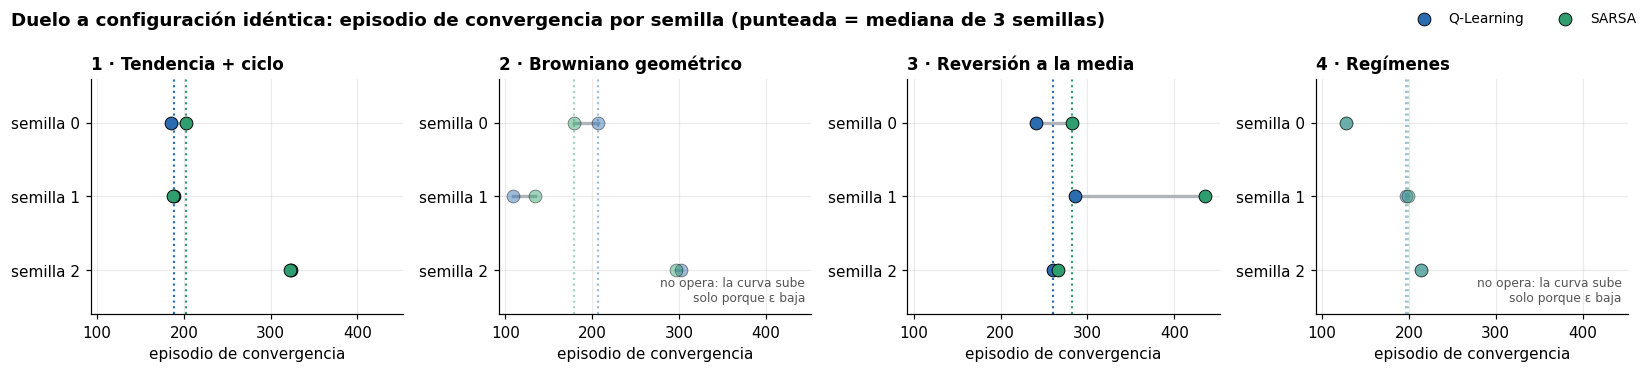

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharex=True)
for ax, m in zip(axes, MARKETS_4):
    d = alg_duelo[alg_duelo.mercado == m]
    gris = MARKET_LABELS[m] in alg_no_opera
    for s in sorted(d.seed.unique()):
        xq = d[(d.agente == "qlearning") & (d.seed == s)].episodios_convergencia.iloc[0]
        xs = d[(d.agente == "sarsa") & (d.seed == s)].episodios_convergencia.iloc[0]
        ax.plot([xq, xs], [s, s], color="#B0B6BC", lw=2.2, zorder=1)
        for a, x in (("qlearning", xq), ("sarsa", xs)):
            ax.scatter(x, s, s=70, color=AGENT_COLORS[a], edgecolor="black", lw=0.6, zorder=3,
                       alpha=0.45 if gris else 1, label=ALG[a] if s == 0 else None)
    for a in ALG:
        ax.axvline(d[d.agente == a].episodios_convergencia.median(), color=AGENT_COLORS[a], ls=":", lw=1.4,
                   alpha=0.45 if gris else 1)
    ax.set_yticks([0, 1, 2], ["semilla 0", "semilla 1", "semilla 2"]); ax.set_ylim(2.6, -0.6)
    ax.set_title(MARKET_LABELS[m], loc="left"); ax.set_xlabel("episodio de convergencia")
    if gris:
        ax.text(0.98, 0.04, "no opera: la curva sube\nsolo porque ε baja", transform=ax.transAxes,
                ha="right", va="bottom", fontsize=8, color="#555")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, fontsize=9)
fig.suptitle("Duelo a configuración idéntica: episodio de convergencia por semilla (punteada = mediana de 3 semillas)",
             x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "04_algoritmos_convergencia"); plt.show()

**Q-Learning converge antes, pero solo con claridad en reversión.**

- **Reversión a la media:** Q-Learning converge antes en **las 3 semillas** (241, 286 y 260 episodios frente a 282, 436
  y 266; mediana 260 frente a 282).
- **Tendencia + ciclo:** la mediana dice 189 frente a 203, pero semilla a semilla es **prácticamente un empate**: la
  diferencia sale de la semilla 0 (185 frente a 203), y en las otras dos SARSA llega un episodio antes (188 frente a 189
  y 322 frente a 323).
- **Mercados 2 y 4:** el agente no opera y la curva sube solo porque ε baja y deja de pagar comisiones aleatorias
  (01 §6). Esos episodios no miden aprendizaje.
- **Con los hiperparámetros de cada uno** (curvas de 2 000 episodios, 01 §6 y 02 §6) la distancia crece: 107 frente a
  200 en el mercado 1 y 262 frente a 356 en reversión. Pero ahí también cambian α, γ y ε, así que no es solo el
  algoritmo.
- El motivo es el esperado: Q-Learning apunta desde el principio a la política greedy (usa el máximo), mientras que
  SARSA persigue un **objetivo que se mueve** (el valor de una ε-greedy cuya ε va bajando) y más ruidoso.
- SARSA **opera menos** con la política greedy final del mercado 1 (56 frente a 66 operaciones por episodio) y, según
  las curvas del 02 §9, gana algo más de recompensa *online* mientras explora, como predice *cliff walking*. Las bandas de
  las dos curvas se solapan casi del todo.

### 3.3 Estabilidad entre semillas

Resultado en test (200 series) de cada una de las 5 semillas finales, con los hiperparámetros de cada algoritmo. En los
mercados 2 y 4 las 10 ejecuciones dan exactamente 0 % (no operan), así que la comparación se centra en los mercados 1 y 3.

In [9]:
def alg_firma(r):
    """Dos ejecuciones con la misma firma (mediana, Sharpe y operaciones en test) son la misma política en la práctica."""
    return (round(r.retorno_mediana, 6), round(r.sharpe, 6), round(r.n_trades, 3))

alg_sem["firma"] = alg_sem.apply(alg_firma, axis=1)
alg_filas_sem = {}
for m in MARKETS_4:
    sub = alg_sem[alg_sem.mercado == m]
    firmas = {a: sub[sub.agente == a].firma for a in ALG}
    for a in ALG:
        v = sub[sub.agente == a].retorno_mediana
        otro = "sarsa" if a == "qlearning" else "qlearning"
        alg_filas_sem[(MARKET_LABELS[m], ALG[a])] = {
            "Mediana": fmt_ret_alg(v.median(), m), "Peor semilla": fmt_ret_alg(v.min(), m),
            "Mejor semilla": fmt_ret_alg(v.max(), m),
            "Resultados distintos": firmas[a].nunique(),
            f"Semillas que repiten un resultado del otro": f"{firmas[a].isin(set(firmas[otro])).sum()} de {len(v)}",
            "Ops/ep. (mediana)": f"{sub[sub.agente == a].n_trades.median():.0f}",
        }
        alg_resumen_fila = next(r for r in alg_resumen if r["agente"] == a and r["mercado"] == m)
        alg_resumen_fila.update(test_mediana=v.median(), test_min=v.min(), test_max=v.max(),
                                test_resultados_distintos=firmas[a].nunique(),
                                test_semillas_comunes=int(firmas[a].isin(set(firmas[otro])).sum()))
tabla_sem = pd.DataFrame(alg_filas_sem).T
display(tabla_sem.style
        .apply(lambda r: ["color:#9AA0A6" if r.name[0] in alg_no_opera else "" for _ in r], axis=1)
        .set_caption("Test, 200 series, 5 semillas por algoritmo · 'resultado' = misma mediana, Sharpe y operaciones"))

# Resumen para el informe: hiperparámetros, duelo y estabilidad en una sola tabla.
alg_out = (pd.DataFrame(alg_resumen).set_index(["agente", "mercado"])
           .join(alg_cfg.rename(columns={"val": "val_mediana"})).reset_index())
alg_out = alg_out[["agente", "mercado", *HP, "val_mediana", "duelo_conv_mediana", "duelo_conv_semillas", "duelo_ops",
                   "duelo_val_mediana", "conv_propios_2000", "test_mediana", "test_min", "test_max",
                   "test_resultados_distintos", "test_semillas_comunes"]]
alg_out.to_csv(RESULTS_DIR / "04_algoritmos.csv", index=False)

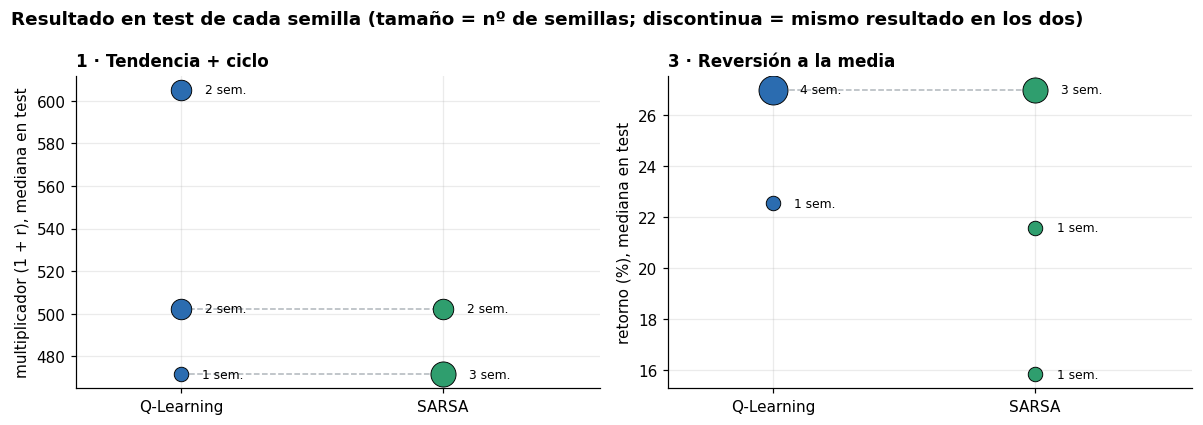

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for ax, m in zip(axes, ["tendencia_ciclo", "reversion_media"]):
    sub = alg_sem[alg_sem.mercado == m]
    y = (lambda v: 1 + v) if m == "tendencia_ciclo" else (lambda v: 100 * v)
    valores = {a: sub[sub.agente == a].retorno_mediana.round(6).value_counts() for a in ALG}
    comunes = set(valores["qlearning"].index) & set(valores["sarsa"].index)
    for v in comunes:                                    # mismo resultado en los dos algoritmos
        ax.plot([0, 1], [y(v), y(v)], color="#B0B6BC", ls="--", lw=1, zorder=1)
    for x, a in enumerate(ALG):
        for v, n in valores[a].items():
            ax.scatter(x, y(v), s=90 * n, color=AGENT_COLORS[a], edgecolor="black", lw=0.6, zorder=3)
            ax.annotate(f"{n} sem.", (x, y(v)), xytext=(10 + 4 * np.sqrt(n), 0), textcoords="offset points",
                        va="center", fontsize=8)
    ax.set_xticks([0, 1], list(ALG.values())); ax.set_xlim(-0.4, 1.6)
    ax.set_ylabel("multiplicador (1 + r), mediana en test" if m == "tendencia_ciclo" else "retorno (%), mediana en test")
    ax.set_title(MARKET_LABELS[m], loc="left")
fig.suptitle("Resultado en test de cada semilla (tamaño = nº de semillas; discontinua = mismo resultado en los dos)",
             x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "04_algoritmos_semillas"); plt.show()

**Pocos resultados distintos, y la mayoría compartidos.**

- **Tendencia + ciclo:** las 5 semillas de SARSA repiten exactamente un resultado de Q-Learning (x502 o x472). Q-Learning
  tiene además un tercer resultado mejor, x605, en 2 semillas. Aquí SARSA **no** es más disperso: su rango es más
  estrecho, pero no alcanza el resultado bueno. Con sus propios hiperparámetros opera incluso algo más (57 frente a 48
  operaciones por episodio), al revés que en el duelo.
- **Reversión a la media:** 3 de 5 semillas de SARSA dan el mismo +27,0 % que 4 de Q-Learning. Las otras dos se quedan
  en políticas peores (+21,6 % y +15,8 %), mientras que la peor de Q-Learning da +22,5 %. Este es el único mercado
  en que SARSA es claramente **menos estable**, coherente con la mayor varianza de su objetivo (02 §7).
- **Mercados 2 y 4:** 0 % en las 10 ejecuciones.

La medida no es la desviación típica: con tan pocos resultados posibles, lo que cambia entre semillas es **qué política
discreta** se encuentra.

### 3.4 Por qué llegan a la misma política y cuándo difieren

**Por qué coinciden.**

1. **Hay muy pocas políticas posibles.** El estado tiene 20 casillas (10 bins de tendencia × posición) y 3 acciones,
   así que el espacio de políticas greedy es pequeño, y los dos algoritmos acaban en la misma tabla de decisiones
   (02 §7 y §8): seguir la tendencia en el mercado 1, comprar tras la caída más fuerte y vender tras la subida más
   fuerte en el 3, y no operar en el 2 y el 4.
2. **ε se apaga.** Con ε 0,99 / 0,01, a partir de unos 460 episodios el 99 % de las acciones son greedy, y entonces
   $Q(S', A') \approx \max_a Q(S', a)$: el objetivo de SARSA y el de Q-Learning casi coinciden (02 §9).
3. **Un error de exploración cuesta poco.** Aquí se paga una comisión del 0,1 % y un paso de exposición; en *cliff
   walking* (slides3 p41–42) caer al acantilado cuesta −100. Por eso la "ruta segura" de SARSA apenas se nota.

**Cuándo difieren.** Si la exploración **no** se apaga, SARSA aprende el valor de una política que seguirá equivocándose
y se vuelve más conservador (02 §5). En reversión, con ε mínimo 0,05 en lugar de 0,01:

In [11]:
alg_eps = []
for a, f in (("qlearning", "01_grid_epsilon"), ("sarsa", "02_grid_epsilon")):
    g = load(f)
    g = g[(g.mercado == "reversion_media") & (g.epsilon_decay == 0.99)]
    for emin in (0.01, 0.05):
        r = g[np.isclose(g.epsilon_min, emin)].sort_values("seed")
        alg_eps.append({"Algoritmo": ALG[a], "γ": alg_num(r.gamma.iloc[0]), "ε mínimo": alg_num(emin),
                        "Ops/ep. (media 3 sem.)": f"{r.n_trades.mean():.0f}",
                        "Ops/ep. por semilla": " · ".join(f"{t:.0f}" for t in r.n_trades),
                        "Peor semilla (validación)": fmt_ret_alg(r.retorno_mediana.min(), "reversion_media")})
display(pd.DataFrame(alg_eps).set_index(["Algoritmo", "ε mínimo"]).style
        .set_caption("Reversión a la media, validación, decaimiento 0,99 · cada algoritmo con su γ de la etapa 2"))

- **SARSA** pasa de 32 a 22 operaciones por episodio de media y su peor semilla cae a **+2,8 %**. **Q-Learning**, que
  usa el máximo, apenas cambia (de 32 a 30) y su peor semilla sube a +34 %.
- **Matiz:** la caída de SARSA no es un recorte uniforme. Dos semillas siguen igual y la tercera **casi deja de operar**
  (1 operación por episodio). Con ε = 5 % estar dentro le parece arriesgado (puede vender por error y pagar comisión), y
  en esa semilla se queda fuera. Es la versión "trading" de la ruta segura de *cliff walking*.
- La comparación no es del todo a igualdad de condiciones: en esta etapa Q-Learning usa γ = 0,5 y SARSA γ = 0,9.

**En resumen:** los dos algoritmos aprenden la **misma estrategia** en los cuatro mercados. Q-Learning converge algo
antes (con claridad solo en reversión) y es algo más estable en reversión. SARSA es más conservador mientras explora,
pero la diferencia solo importa si ε no se apaga. Con este entorno y este estado, **el algoritmo pesa mucho menos que
el estado y los hiperparámetros** (α pequeño, γ por mercado).

## 4. Más allá de los mínimos

El notebook 03 amplía la práctica en tres direcciones y un anexo de robustez:

- **Estado enriquecido:** al estado base (tendencia corta × posición, 20 celdas) se le añaden la distancia a MA30 y la volatilidad de 20 retornos (180 celdas).
- **Dos mercados extra:** tendencia persistente (señal con memoria) y difusión con saltos (riesgo impredecible).
- **Serie real:** S&P 500 de FRED, con train 2017–2021, validación 2022–2023 y test 2024–2025 (D-0.5), y un walk-forward anual de 2019 a 2025.
- **Anexo (§9 del 03):** cambia un solo factor cada vez: indicador, episodios, placebos, comisión, algoritmo TD y recompensa (D-1.4).

Aquí solo se resume lo que aporta. Las tablas completas, el protocolo y las comprobaciones están en el 03.

> **Cifras no comparables con §1.** El 03 compara base y enriquecido **con una configuración fija** (α=0,001, γ=0,9, ε 1→0,01, 800 episodios, 5 semillas; D-1.2), no con los hiperparámetros ajustados por mercado en 01–02. Es una ablación con el mismo presupuesto para los dos estados: sirve para medir qué aporta el estado, no para mejorar las tablas de §1.

In [12]:
# Fuentes: lo que guardó el 03 (secciones 1–8 y anexo §9). Aquí no se entrena nada.
ext_resumen = load("03_extras")
ext_deltas = load("03_estado_deltas")
ext_anexo = load("03_anexo")
ext_ctrl = load("03_anexo_controles")

EXT_LABELS = {"reversion_media": "Reversión a la media", "regimenes": "Regímenes",
              "tendencia_persistente": "Tendencia persistente", "saltos": "Difusión + saltos",
              "sp500_real": "S&P 500 · real", "tendencia_ciclo": "Tendencia + ciclo"}
EXT_SINT = ["reversion_media", "regimenes", "tendencia_persistente", "saltos"]


def ext_pct(x, signo=True):
    """0.231 -> '+23,1 %' (formato de los notebooks)."""
    return (f"{100 * x:+.1f} %" if signo else f"{100 * x:.1f} %").replace(".", ",")


def ext_pp(x):
    return f"{100 * x:+.1f} pp".replace(".", ",")


def ext_ret(agente, mercado, col="retorno_mediana"):
    return ext_resumen.set_index(["agente", "mercado"]).loc[(agente, mercado), col]


def ext_anx(experimento, mercado, **filtros):
    sel = ext_anexo[(ext_anexo.experimento == experimento) & (ext_anexo.mercado == mercado)]
    for k, v in filtros.items():
        sel = sel[sel[k] == v]
    return sel


def ext_bh(mercado, coste=0.001, anio=0, col="retorno_mediana"):
    c = ext_ctrl
    return c[(c.agente == "buy_hold") & (c.mercado == mercado) & (c.coste == coste) & (c.anio == anio)][col].item()


# --- Datos de cada fila de la tabla síntesis, leídos de los CSV --------------------------------
dl = ext_deltas.set_index(["mercado", "algoritmo"])
fila_estado = "; ".join(
    f"{EXT_LABELS[m]} {ext_pp(dl.loc[(m, 'qlearning'), 'delta_mediana'])} [{ext_pp(dl.loc[(m, 'qlearning'), 'ic95_inf'])}, "
    f"{ext_pp(dl.loc[(m, 'qlearning'), 'ic95_sup'])}]" for m in ["reversion_media", "tendencia_persistente", "regimenes"])
sarsa_rango = (dl.xs("sarsa", level="algoritmo").loc[["reversion_media", "tendencia_persistente", "regimenes"], "delta_mediana"])

ind = ext_anexo[ext_anexo.experimento == "indicadores"].pivot(index="mercado", columns="estado", values="retorno_mediana")

wf = ext_anexo[ext_anexo.experimento == "walk_forward"].pivot(index="anio", columns="estado", values="retorno_mediana")
wf["buy_hold"] = [ext_bh("sp500_anual", anio=a) for a in wf.index]
wf_dd = ext_anexo[ext_anexo.experimento == "walk_forward"].pivot(index="anio", columns="estado", values="max_drawdown")
wf_dd["buy_hold"] = [ext_bh("sp500_anual", anio=a, col="max_drawdown") for a in wf.index]
wf_base_gana = int((wf.base > wf.buy_hold + 1e-9).sum())
wf_enr_gana = int((wf.enriquecido > wf.buy_hold + 1e-9).sum())
wf_enr_dd = int((wf_dd.enriquecido < wf_dd.buy_hold - 1e-9).sum())

pla = ext_anexo[ext_anexo.experimento == "placebo"].set_index(["mercado", "estado"]).retorno_mediana
com = ext_anexo[ext_anexo.experimento == "comision"].set_index(["mercado", "coste"])
alg = ext_anexo[ext_anexo.experimento == "algoritmos"].groupby("mercado").retorno_mediana.agg(["min", "max"])
pre = ext_anexo[ext_anexo.experimento == "presupuesto"].set_index(["mercado", "n_episodes"]).retorno_mediana
rec = ext_anexo[ext_anexo.experimento == "recompensa"].pivot(index="mercado", columns="recompensa", values="retorno_mediana")
rec_sin_ciclo = (rec.log - rec.taller).drop("tendencia_ciclo")

sint = [
    ("Estado enriquecido (§6)",
     "20 → 180 celdas; diferencia emparejada por historia, enriquecido − base, IC bootstrap 95 %",
     f"Q-Learning: {fila_estado}. SARSA: " + ", ".join(ext_pp(v) for v in sarsa_rango) + " en el mismo orden. "
     f"Saltos: {ext_pct(dl.loc[('saltos', 'qlearning'), 'delta_mediana'], False).replace(' %', ' pp')} (no opera con ningún estado)",
     "Mejora con IC por encima de cero en los tres mercados con memoria, igual con los dos algoritmos"),
    ("¿Qué indicador? (§9.1)",
     "Base, +MA30, +volatilidad o ambos, por separado",
     f"Reversión: MA30 {ext_pct(ind.loc['reversion_media', 'ma30'])} (ambos {ext_pct(ind.loc['reversion_media', 'enriquecido'])}). "
     f"Tendencia: MA30 {ext_pct(ind.loc['tendencia_persistente', 'ma30'])} (ambos {ext_pct(ind.loc['tendencia_persistente', 'enriquecido'])}). "
     f"Regímenes: volatilidad {ext_pct(ind.loc['regimenes', 'vol'])}, MA30 {ext_pct(ind.loc['regimenes', 'ma30'])}",
     "Cada mercado usa el indicador que predice su mecanismo"),
    ("Mercados extra (§6)",
     "Tendencia persistente y difusión con saltos",
     f"Tendencia: Q enr. {ext_pct(ext_ret('qlearning_enriquecido', 'tendencia_persistente'))}, SARSA enr. "
     f"{ext_pct(ext_ret('sarsa_enriquecido', 'tendencia_persistente'))}, buy & hold {ext_pct(ext_ret('buy_hold', 'tendencia_persistente'))}. "
     f"Saltos: todos los agentes {ext_pct(ext_ret('qlearning_enriquecido', 'saltos'))}, buy & hold {ext_pct(ext_ret('buy_hold', 'saltos'))}",
     "La persistencia se aprovecha. Ante saltos imprevisibles el agente no opera, y eso no es anticipar caídas"),
    ("S&P 500 · test 2024–2025 (§7)",
     "Una trayectoria real, 5 semillas sobre los mismos precios",
     f"Buy & hold {ext_pct(ext_ret('buy_hold', 'sp500_real'))}. Base {ext_pct(ext_ret('qlearning_base', 'sp500_real'))} "
     f"({ext_ret('qlearning_base', 'sp500_real', 'n_trades'):.0f} operación). Enriquecido Q {ext_pct(ext_ret('qlearning_enriquecido', 'sp500_real'))} "
     f"/ SARSA {ext_pct(ext_ret('sarsa_enriquecido', 'sp500_real'))}, caída máx. {ext_pct(ext_ret('qlearning_enriquecido', 'sp500_real', 'max_drawdown'), False)} "
     f"frente a {ext_pct(ext_ret('qlearning_base', 'sp500_real', 'max_drawdown'), False)}",
     "El base equivale a comprar y mantener. El enriquecido cambia rentabilidad por menor caída"),
    ("Walk-forward anual (§9.7)",
     "Entrenar con los años anteriores y evaluar 2019, …, 2025",
     f"El base supera a buy & hold en {wf_base_gana} de {len(wf)} años y el enriquecido en {wf_enr_gana}; "
     f"el enriquecido reduce la caída máxima en {wf_enr_dd} de {len(wf)}",
     "No hay ventaja persistente en el índice real"),
    ("Placebos (§9.3)",
     "Browniano y S&P 500 con retornos barajados",
     f"Browniano: base {ext_pct(pla[('browniano', 'base')])}, enr. {ext_pct(pla[('browniano', 'enriquecido')])}. "
     f"Barajado: base {ext_pct(pla[('sp500_barajado', 'base')])}, enr. {ext_pct(pla[('sp500_barajado', 'enriquecido')])}, "
     f"buy & hold {ext_pct(ext_bh('sp500_barajado'))}",
     "Sin señal no aparece una ventaja falsa"),
    ("Presupuesto (§9.2)",
     "800, 1 600 y 3 200 episodios",
     f"S&P 500 {ext_pct(pre[('sp500_real', 800)])} → {ext_pct(pre[('sp500_real', 3200)])}; "
     f"reversión {ext_pct(pre[('reversion_media', 800)])} → {ext_pct(pre[('reversion_media', 3200)])}",
     "El estado de 180 celdas no está infraentrenado"),
    ("Comisión (§9.4)",
     "Reentrenar con comisión de 0 % a 0,5 %",
     f"Reversión {ext_pct(com.loc[('reversion_media', 0.0), 'retorno_mediana'])} ({com.loc[('reversion_media', 0.0), 'n_trades']:.0f} ops.) → "
     f"{ext_pct(com.loc[('reversion_media', 0.005), 'retorno_mediana'])} ({com.loc[('reversion_media', 0.005), 'n_trades']:.0f} ops.). "
     f"Regímenes {ext_pct(com.loc[('regimenes', 0.0025), 'retorno_mediana'])} desde el 0,25 %",
     "El agente opera menos al subir la comisión. La ventaja en regímenes es la más fina"),
    ("Algoritmo TD (§9.5)",
     "Q-Learning, SARSA, Expected SARSA y Double Q",
     "; ".join(f"{EXT_LABELS[m]} [{ext_pct(alg.loc[m, 'min'])}, {ext_pct(alg.loc[m, 'max'])}]"
               for m in ["reversion_media", "regimenes", "tendencia_persistente", "sp500_real"]),
     "Los cuatro algoritmos acaban casi en el mismo sitio"),
    ("Recompensa log (§9.6)",
     "log(B<sub>t</sub>/B<sub>t−1</sub>) en lugar del retorno simple",
     f"Fuera de tendencia + ciclo, como mucho {ext_pp(rec_sin_ciclo.abs().max())} frente a la recompensa del taller",
     "La forma de la recompensa no cambia la conclusión"),
]
ext_tabla = "| Prueba (03) | Qué se probó | Qué salió | Qué significa |\n|---|---|---|---|\n" + "\n".join(
    f"| **{a}** | {b} | {c} | {d} |" for a, b, c, d in sint)
display(Markdown(ext_tabla))

| Prueba (03) | Qué se probó | Qué salió | Qué significa |
|---|---|---|---|
| **Estado enriquecido (§6)** | 20 → 180 celdas; diferencia emparejada por historia, enriquecido − base, IC bootstrap 95 % | Q-Learning: Reversión a la media +23,1 pp [+20,5 pp, +26,5 pp]; Tendencia persistente +19,1 pp [+16,1 pp, +23,4 pp]; Regímenes +7,8 pp [+5,5 pp, +10,6 pp]. SARSA: +23,7 pp, +18,4 pp, +7,8 pp en el mismo orden. Saltos: 0,0 pp (no opera con ningún estado) | Mejora con IC por encima de cero en los tres mercados con memoria, igual con los dos algoritmos |
| **¿Qué indicador? (§9.1)** | Base, +MA30, +volatilidad o ambos, por separado | Reversión: MA30 +44,0 % (ambos +42,8 %). Tendencia: MA30 +120,6 % (ambos +123,8 %). Regímenes: volatilidad +8,5 %, MA30 +0,0 % | Cada mercado usa el indicador que predice su mecanismo |
| **Mercados extra (§6)** | Tendencia persistente y difusión con saltos | Tendencia: Q enr. +123,8 %, SARSA enr. +128,7 %, buy & hold +22,8 %. Saltos: todos los agentes +0,0 %, buy & hold -22,4 % | La persistencia se aprovecha. Ante saltos imprevisibles el agente no opera, y eso no es anticipar caídas |
| **S&P 500 · test 2024–2025 (§7)** | Una trayectoria real, 5 semillas sobre los mismos precios | Buy & hold +44,2 %. Base +45,9 % (1 operación). Enriquecido Q +28,3 % / SARSA +29,9 %, caída máx. 11,4 % frente a 18,9 % | El base equivale a comprar y mantener. El enriquecido cambia rentabilidad por menor caída |
| **Walk-forward anual (§9.7)** | Entrenar con los años anteriores y evaluar 2019, …, 2025 | El base supera a buy & hold en 1 de 7 años y el enriquecido en 0; el enriquecido reduce la caída máxima en 4 de 7 | No hay ventaja persistente en el índice real |
| **Placebos (§9.3)** | Browniano y S&P 500 con retornos barajados | Browniano: base +0,0 %, enr. +0,0 %. Barajado: base +44,0 %, enr. +11,1 %, buy & hold +44,2 % | Sin señal no aparece una ventaja falsa |
| **Presupuesto (§9.2)** | 800, 1 600 y 3 200 episodios | S&P 500 +28,3 % → +28,7 %; reversión +42,8 % → +42,8 % | El estado de 180 celdas no está infraentrenado |
| **Comisión (§9.4)** | Reentrenar con comisión de 0 % a 0,5 % | Reversión +45,8 % (61 ops.) → +23,0 % (6 ops.). Regímenes +0,0 % desde el 0,25 % | El agente opera menos al subir la comisión. La ventaja en regímenes es la más fina |
| **Algoritmo TD (§9.5)** | Q-Learning, SARSA, Expected SARSA y Double Q | Reversión a la media [+42,3 %, +43,9 %]; Regímenes [+6,5 %, +7,8 %]; Tendencia persistente [+123,8 %, +128,7 %]; S&P 500 · real [+28,3 %, +32,5 %] | Los cuatro algoritmos acaban casi en el mismo sitio |
| **Recompensa log (§9.6)** | log(B<sub>t</sub>/B<sub>t−1</sub>) en lugar del retorno simple | Fuera de tendencia + ciclo, como mucho +2,7 pp frente a la recompensa del taller | La forma de la recompensa no cambia la conclusión |

La figura reúne las tres ideas. **(a)** Aporte del estado enriquecido con su intervalo. **(b)** Cuánto se mueve el retorno al cambiar el estado frente a lo que se mueve al cambiar el algoritmo, los episodios o la recompensa. **(c)** El S&P 500 año a año, medido frente a buy & hold.

,Cambiar el estado,"Cambiar algoritmo, episodios o recompensa",Δ emparejado Q (enr. − base)
Reversión a la media,"25,9 pp","1,7 pp","23,1 pp"
Tendencia persistente,"19,3 pp","4,9 pp","19,1 pp"
Regímenes,"8,5 pp","1,7 pp","7,8 pp"
S&P 500 · real,"17,5 pp","4,2 pp",—


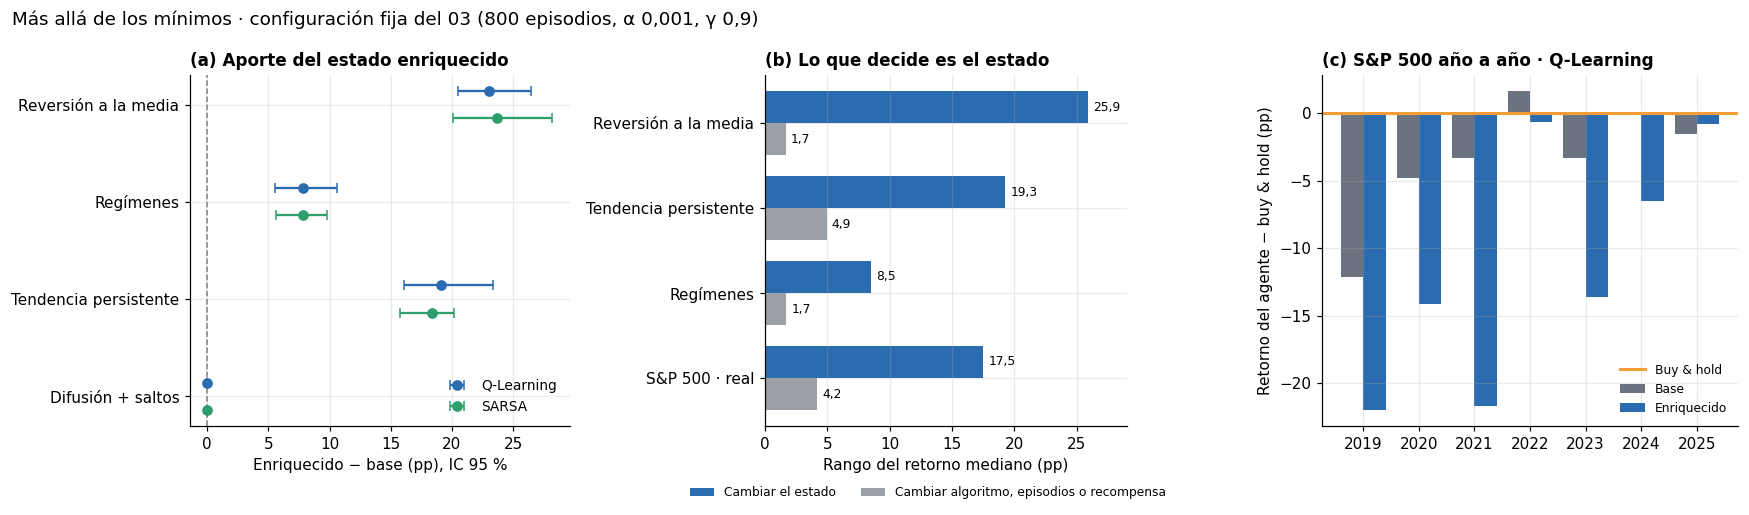

In [13]:
# (b) Rango del retorno mediano (pp) al cambiar el estado frente a cambiar el resto, con Q-Learning y estado enriquecido de referencia.
EXT_MERC_B = ["reversion_media", "tendencia_persistente", "regimenes", "sp500_real"]
ext_rangos = []
for m in EXT_MERC_B:
    estados = ext_anx("indicadores", m).retorno_mediana
    otros = pd.concat([ext_anx("algoritmos", m).retorno_mediana, ext_anx("presupuesto", m).retorno_mediana,
                       ext_anx("recompensa", m).retorno_mediana])
    ext_rangos.append({"mercado": m,
                       "rango_estado_pp": 100 * (estados.max() - estados.min()),
                       "rango_algoritmo_presupuesto_recompensa_pp": 100 * (otros.max() - otros.min()),
                       "delta_emparejado_q_pp": 100 * dl.loc[(m, "qlearning"), "delta_mediana"] if m != "sp500_real" else np.nan})
ext_rangos = pd.DataFrame(ext_rangos)
ext_rangos.to_csv(RESULTS_DIR / "04_extras.csv", index=False)
display(ext_rangos.assign(mercado=ext_rangos.mercado.map(EXT_LABELS)).set_index("mercado")
        .rename(columns={"rango_estado_pp": "Cambiar el estado",
                         "rango_algoritmo_presupuesto_recompensa_pp": "Cambiar algoritmo, episodios o recompensa",
                         "delta_emparejado_q_pp": "Δ emparejado Q (enr. − base)"})
        .rename_axis(None)
        .style.format(lambda v: "—" if pd.isna(v) else f"{v:.1f} pp".replace(".", ","))
        .set_caption("Rango del retorno mediano entre variantes (máximo − mínimo) · Q-Learning, configuración fija del 03"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.05, 1, 1.15]})

# (a) Aporte del estado: mediana de diferencias emparejadas e IC 95 %.
ax = axes[0]
for i, m in enumerate(EXT_SINT):
    for k, a in enumerate(["qlearning", "sarsa"]):
        r = dl.loc[(m, a)]
        y = i + (k - .5) * .28
        ax.errorbar(100 * r.delta_mediana, y, xerr=[[100 * (r.delta_mediana - r.ic95_inf)], [100 * (r.ic95_sup - r.delta_mediana)]],
                    fmt="o", capsize=3, color=AGENT_COLORS[a], label=("Q-Learning" if a == "qlearning" else "SARSA") if i == 0 else None)
ax.set_yticks(range(len(EXT_SINT)), [EXT_LABELS[m] for m in EXT_SINT]); ax.invert_yaxis()
ax.axvline(0, color="gray", ls="--", lw=1)
ax.set_xlabel("Enriquecido − base (pp), IC 95 %")
ax.set_title("(a) Aporte del estado enriquecido", loc="left"); ax.legend(loc="lower right")

# (b) Estado frente al resto de factores.
ax = axes[1]
y = np.arange(len(EXT_MERC_B))
ax.barh(y - .19, ext_rangos.rango_estado_pp, .38, color=AGENT_COLORS["qlearning"], label="Cambiar el estado")
ax.barh(y + .19, ext_rangos.rango_algoritmo_presupuesto_recompensa_pp, .38, color=AGENT_COLORS["aleatorio"],
        label="Cambiar algoritmo, episodios o recompensa")
for yy, v1, v2 in zip(y, ext_rangos.rango_estado_pp, ext_rangos.rango_algoritmo_presupuesto_recompensa_pp):
    ax.text(v1 + .4, yy - .19, f"{v1:.1f}".replace(".", ","), va="center", fontsize=8)
    ax.text(v2 + .4, yy + .19, f"{v2:.1f}".replace(".", ","), va="center", fontsize=8)
ax.set_yticks(y, [EXT_LABELS[m] for m in EXT_MERC_B]); ax.invert_yaxis()
ax.set_xlabel("Rango del retorno mediano (pp)")
ax.set_xlim(0, 1.12 * ext_rangos.rango_estado_pp.max())
ax.set_title("(b) Lo que decide es el estado", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(.45, -.14), ncol=2, fontsize=8)

# (c) S&P 500: diferencia frente a buy & hold en cada año de test.
ax = axes[2]
x = np.arange(len(wf))
ax.bar(x - .2, 100 * (wf.base - wf.buy_hold), .4, color="#6B7280", label="Base")
ax.bar(x + .2, 100 * (wf.enriquecido - wf.buy_hold), .4, color=AGENT_COLORS["qlearning"], label="Enriquecido")
ax.axhline(0, color=AGENT_COLORS["buy_hold"], lw=2, label="Buy & hold")
ax.set_xticks(x, wf.index)
ax.set_ylabel("Retorno del agente − buy & hold (pp)")
ax.set_title("(c) S&P 500 año a año · Q-Learning", loc="left"); ax.legend(loc="lower right", fontsize=8)

fig.suptitle("Más allá de los mínimos · configuración fija del 03 (800 episodios, α 0,001, γ 0,9)", x=.01, ha="left")
fig.tight_layout(); savefig(fig, "04_extras_resumen"); plt.show()

In [14]:
# Lectura con cifras de los CSV.
rv, tp, rg = (dl.loc[(m, "qlearning"), "delta_mediana"] for m in ["reversion_media", "tendencia_persistente", "regimenes"])
rb = ext_rangos.set_index("mercado")
display(Markdown(f"""
**Lectura.**

- **Lo que decide es la información del estado, no el algoritmo.** Con el mismo presupuesto, el estado enriquecido mejora el retorno en los tres sintéticos con memoria: {ext_pp(rv)} en reversión, {ext_pp(tp)} en tendencia persistente y {ext_pp(rg)} en regímenes, con Q-Learning y el intervalo por encima de cero. SARSA da lo mismo. La mejora viene de **un indicador por mercado**: MA30 en reversión y tendencia, volatilidad en regímenes. En reversión, cambiar el estado mueve el retorno {f"{rb.loc['reversion_media', 'rango_estado_pp']:.1f}".replace(".", ",")} pp. Cambiar de algoritmo TD, multiplicar los episodios por cuatro o usar la recompensa logarítmica lo mueve como mucho {f"{rb.loc['reversion_media', 'rango_algoritmo_presupuesto_recompensa_pp']:.1f}".replace(".", ",")} pp.
- **Donde no hay señal, el agente no se la inventa.** En el browniano y en los saltos no opera ({ext_pct(pla[('browniano', 'enriquecido')])}). Superar a buy & hold quedándose en efectivo no es anticipar caídas.
- **En el índice real no hay ventaja sobre buy & hold.** En 2024–2025 el base hace {ext_ret('qlearning_base', 'sp500_real', 'n_trades'):.0f} operación y queda en {ext_pct(ext_ret('qlearning_base', 'sp500_real'))}, frente a {ext_pct(ext_ret('buy_hold', 'sp500_real'))}: equivale a comprar y mantener. El enriquecido cambia rentabilidad por caída máxima. En el walk-forward queda por debajo de buy & hold los {len(wf)} años. Es una sola historia por año y cinco semillas sobre los mismos precios, sin dividendos ni costes reales. No es una validación operativa.
- **Límites.** Los IC condicionan a las políticas entrenadas y no corrigen comparaciones múltiples. Las variantes se fijaron antes de mirar el test (D-1.2, D-1.4).
"""))


**Lectura.**

- **Lo que decide es la información del estado, no el algoritmo.** Con el mismo presupuesto, el estado enriquecido mejora el retorno en los tres sintéticos con memoria: +23,1 pp en reversión, +19,1 pp en tendencia persistente y +7,8 pp en regímenes, con Q-Learning y el intervalo por encima de cero. SARSA da lo mismo. La mejora viene de **un indicador por mercado**: MA30 en reversión y tendencia, volatilidad en regímenes. En reversión, cambiar el estado mueve el retorno 25,9 pp. Cambiar de algoritmo TD, multiplicar los episodios por cuatro o usar la recompensa logarítmica lo mueve como mucho 1,7 pp.
- **Donde no hay señal, el agente no se la inventa.** En el browniano y en los saltos no opera (+0,0 %). Superar a buy & hold quedándose en efectivo no es anticipar caídas.
- **En el índice real no hay ventaja sobre buy & hold.** En 2024–2025 el base hace 1 operación y queda en +45,9 %, frente a +44,2 %: equivale a comprar y mantener. El enriquecido cambia rentabilidad por caída máxima. En el walk-forward queda por debajo de buy & hold los 7 años. Es una sola historia por año y cinco semillas sobre los mismos precios, sin dividendos ni costes reales. No es una validación operativa.
- **Límites.** Los IC condicionan a las políticas entrenadas y no corrigen comparaciones múltiples. Las variantes se fijaron antes de mirar el test (D-1.2, D-1.4).


## 5. Figuras y tabla para el informe

El informe tiene **2 páginas como máximo** (D-3.1). Caben una tabla y tres figuras pequeñas, y cada una tiene que leerse
sola. Se dibujan al ancho real de la página (17 cm) con letra de 9 pt, para que el PDF no tenga que reducirlas:

| Hueco del informe | Figura | Qué cuenta |
|---|---|---|
| Resultados (mínimos) | `04_informe_rendimiento.png` | Los cuatro agentes en los cuatro mercados, en test |
| Q-Learning frente a SARSA | `04_informe_convergencia.png` | Quién converge antes y quién opera menos, semilla a semilla |
| Más allá de los mínimos | `04_informe_mas_alla.png` | Estado enriquecido en sintéticos y S&P 500 año a año |
| Tabla | `results/04_informe_tabla.md` | Rendimiento, operaciones y convergencia en una sola tabla |

Todo sale de `results/*.csv`; aquí no se entrena nada.

In [15]:
# Estilo del informe: tamaño real de página (17 cm) y letra de 9 pt. Solo afecta a las figuras de esta sección.
INFORME_RC = {"font.size": 9, "axes.titlesize": 9.5, "axes.labelsize": 9, "xtick.labelsize": 9,
              "ytick.labelsize": 9, "legend.fontsize": 9, "savefig.dpi": 220}
ANCHO_INFORME = 17 / 2.54  # pulgadas
GRIS_BASE = "#6B7280"
AGENT_LABELS_INF = {"aleatorio": "Aleatorio", "buy_hold": "Buy & hold", "qlearning": "Q-Learning", "sarsa": "SARSA"}


def num_es(x, dec=1):
    """Número con coma decimal y signo menos tipográfico."""
    return f"{x:.{dec}f}".replace(".", ",").replace("-", "−")


def ret_es(r, mercado=None, dec=1):
    """Retorno como en el informe: múltiplo del capital en el mercado 1 y porcentaje en el resto."""
    if mercado == "tendencia_ciclo":
        m = 1 + r
        return "x" + (num_es(m, 1) if m < 100 else num_es(m, 0))
    if r == 0:
        return "0 %"
    return ("+" if r > 0 else "") + num_es(100 * r, dec) + " %"


# Resultados finales en test (200 series, mediana) y por semilla
baselines_inf = load("00_baselines")
finales_inf = pd.concat([baselines_inf, load("01_qlearning"), load("02_sarsa")], ignore_index=True)
semillas_inf = pd.concat([load("01_qlearning_semillas"), load("02_sarsa_semillas")], ignore_index=True)
duelo_inf = load("02_duelo")
assert set(semillas_inf.split) == {"test"} and set(duelo_inf.split) == {"val"}
final_ret = finales_inf.pivot(index="mercado", columns="agente", values="retorno_mediana").loc[MARKETS_4]
final_ops = finales_inf.pivot(index="mercado", columns="agente", values="n_trades").loc[MARKETS_4]
rango_semillas = semillas_inf.groupby(["mercado", "agente"]).retorno_mediana.agg(["min", "max"])

### 5.1 Figura 1 · Rendimiento en test

Un panel por mercado, porque las escalas no se pueden comparar: en el mercado 1 buy & hold multiplica el capital por 33,6
y los agentes por casi 500, así que ese panel usa el **múltiplo del capital en escala logarítmica**. Los otros tres
están en porcentaje. Las barras son la mediana en las 200 series de test; en Q-Learning y SARSA, la mediana de 5
semillas, y las marcas negras son cada semilla.

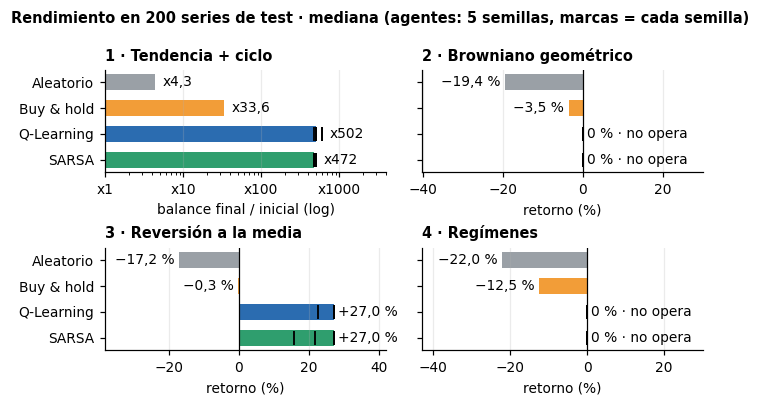

In [16]:
ORDEN_AGENTES = ["aleatorio", "buy_hold", "qlearning", "sarsa"]

with plt.rc_context(INFORME_RC):
    fig, axes = plt.subplots(2, 2, figsize=(ANCHO_INFORME - 0.2, 3.7))
    for ax, mercado in zip(axes.flat, MARKETS_4):
        es_m1 = mercado == "tendencia_ciclo"
        y = np.arange(len(ORDEN_AGENTES))[::-1]
        vals = final_ret.loc[mercado, ORDEN_AGENTES].to_numpy()
        base = 1.0 if es_m1 else 0.0
        plot_vals = 1 + vals if es_m1 else 100 * vals
        ax.barh(y, plot_vals - base, left=base, height=0.62,
                color=[AGENT_COLORS[a] for a in ORDEN_AGENTES])
        extremos = plot_vals.copy()
        for yi, agente in zip(y, ORDEN_AGENTES):
            if agente in ("qlearning", "sarsa"):
                s = semillas_inf.query("mercado == @mercado and agente == @agente").retorno_mediana.to_numpy()
                s_plot = 1 + s if es_m1 else 100 * s
                ax.scatter(s_plot, np.full(len(s_plot), yi), marker="|", s=90, color="black", lw=1.2, zorder=3)
                extremos[ORDEN_AGENTES.index(agente)] = s_plot.max() if plot_vals[ORDEN_AGENTES.index(agente)] >= 0 else s_plot.min()
        if es_m1:
            ax.set_xscale("log")
            ax.set_xlim(1, 4000)
            ax.set_xticks([1, 10, 100, 1000], ["x1", "x10", "x100", "x1000"])
            ax.set_xlabel("balance final / inicial (log)")
            for yi, v, e, a in zip(y, vals, extremos, ORDEN_AGENTES):
                ax.text(e * 1.25, yi, ret_es(v, mercado), va="center", ha="left")
        else:
            span = max(30.0, plot_vals.max() + 15)
            lo = min(plot_vals.min(), 0) - 21
            ax.set_xlim(lo, span)
            ax.axvline(0, color="black", lw=0.8)
            ax.set_xlabel("retorno (%)")
            for yi, v, e, a in zip(y, vals, extremos, ORDEN_AGENTES):
                if v == 0:
                    ax.text(1, yi, "0 % · no opera", va="center", ha="left")
                elif v > 0:
                    ax.text(e + 1.2, yi, ret_es(v), va="center", ha="left")
                else:
                    ax.text(e - 1.2, yi, ret_es(v), va="center", ha="right")
        ax.set_yticks(y, [AGENT_LABELS_INF[a] for a in ORDEN_AGENTES])
        ax.set_title(MARKET_LABELS[mercado], loc="left")
        ax.grid(axis="y", visible=False)
    for ax in axes[:, 1]:
        ax.tick_params(labelleft=False)
    fig.suptitle("Rendimiento en 200 series de test · mediana (agentes: 5 semillas, marcas = cada semilla)",
                 x=0.01, ha="left", fontsize=9.5, fontweight="bold")
    fig.tight_layout(h_pad=0.6, w_pad=1.0)
    savefig(fig, "04_informe_rendimiento")
    plt.show()

**Lectura.** Los dos algoritmos encuentran la misma estrategia y baten a los dos baselines en los cuatro mercados.
En el 1 y el 3 ganan dinero; en el 2 y el 4 ganan **no operando**, que es lo correcto (el browniano no tiene señal y el
estado no ve el régimen, D-2.4). Las marcas casi se solapan: varias semillas llegan a la misma tabla de decisiones.

**Pie para el informe:** *Figura 1. Mediana del retorno en las 200 series de test. Agentes con hiperparámetros
elegidos en validación; mediana de 5 semillas (marcas: cada semilla). Mercado 1 en múltiplo del capital, escala log.*

### 5.2 Figura 2 · Q-Learning frente a SARSA

La pregunta del profesor es qué algoritmo converge antes. Se responde con el **duelo** de `02_duelo.csv`: misma
configuración, mismas 3 semillas y mismas series (D-2.5). Se muestran los mercados 1 y 3, los únicos en los que el
agente opera; en el 2 y el 4 la curva sube solo porque ε baja y deja de pagar comisiones. Las líneas grises unen la
misma semilla en los dos algoritmos.

Las curvas completas están en `02_duelo_curvas.png`. Son buenas para la presentación, pero a 17 cm su letra queda en
menos de 5 pt, así que para el PDF es mejor esta versión resumida.

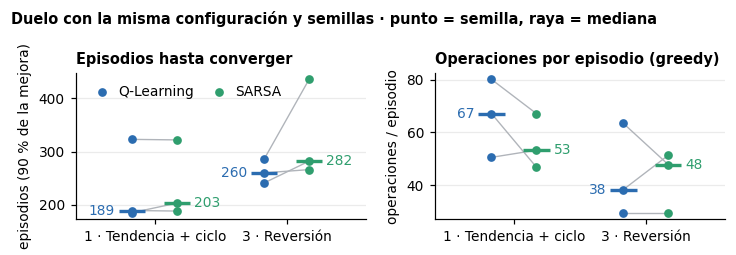

In [17]:
MERCADOS_OPERAN = ["tendencia_ciclo", "reversion_media"]
METRICAS_DUELO = [("episodios_convergencia", "Episodios hasta converger", "episodios (90 % de la mejora)"),
                  ("n_trades", "Operaciones por episodio (greedy)", "operaciones / episodio")]

with plt.rc_context(INFORME_RC):
    fig, axes = plt.subplots(1, 2, figsize=(ANCHO_INFORME, 2.3))
    for ax, (col, titulo, ylabel) in zip(axes, METRICAS_DUELO):
        for i, mercado in enumerate(MERCADOS_OPERAN):
            d = duelo_inf.query("mercado == @mercado").pivot(index="seed", columns="agente", values=col)
            xq, xs = i - 0.17, i + 0.17
            for seed, fila in d.iterrows():
                ax.plot([xq, xs], [fila.qlearning, fila.sarsa], color="#B0B4BA", lw=0.9, zorder=1)
            for x, agente in [(xq, "qlearning"), (xs, "sarsa")]:
                ax.scatter(np.full(len(d), x), d[agente], color=AGENT_COLORS[agente], s=22, zorder=3,
                           label=AGENT_LABELS_INF[agente] if i == 0 else None)
                med = d[agente].median()
                ax.hlines(med, x - 0.1, x + 0.1, color=AGENT_COLORS[agente], lw=2.2, zorder=2)
                ax.text(x + (-0.13 if agente == "qlearning" else 0.13), med, num_es(med, 0),
                        ha="right" if agente == "qlearning" else "left", va="center", color=AGENT_COLORS[agente])
        ax.set_xticks(range(len(MERCADOS_OPERAN)), ["1 · Tendencia + ciclo", "3 · Reversión"])
        ax.set_xlim(-0.6, len(MERCADOS_OPERAN) - 0.4)
        ax.set_ylabel(ylabel)
        ax.set_title(titulo, loc="left")
        ax.grid(axis="x", visible=False)
    axes[0].legend(loc="upper left", ncol=2, handletextpad=0.2, columnspacing=0.8)
    fig.suptitle("Duelo con la misma configuración y semillas · punto = semilla, raya = mediana",
                 x=0.01, ha="left", fontsize=9.5, fontweight="bold")
    fig.tight_layout(w_pad=1.5)
    savefig(fig, "04_informe_convergencia")
    plt.show()

# Comparación semilla a semilla para el texto
conv_pares = duelo_inf.query("mercado in @MERCADOS_OPERAN").pivot_table(
    index=["mercado", "seed"], columns="agente", values="episodios_convergencia")
conv_pares["Q-L antes"] = conv_pares.qlearning < conv_pares.sarsa
conv_pares.rename(index=MARKET_LABELS).style.format({"qlearning": "{:.0f}", "sarsa": "{:.0f}"})

**Lectura.** Con la misma configuración, **Q-Learning converge antes en mediana** (189 frente a 203 episodios en el
mercado 1 y 260 frente a 282 en reversión). En operaciones no hay un patrón común: en el mercado 1 la política
greedy de SARSA opera menos (53 frente a 67, como predice *cliff walking*), pero en reversión opera más (48 frente a
38). Semilla a semilla la ventaja de Q-Learning solo es clara en reversión (3 de 3 semillas). En el mercado 1
gana en una semilla y en las otras dos los dos algoritmos convergen con un episodio de diferencia. Es una diferencia
pequeña, coherente con que un error de exploración cueste solo un 0,1 % (D-2.5).

**Pie para el informe:** *Figura 2. Duelo Q-Learning–SARSA con la misma configuración y semillas: episodios hasta
alcanzar el 90 % de la mejora de la recompensa (media móvil 50) y operaciones por episodio de la política greedy en
validación. Punto = semilla; raya = mediana.*

### 5.3 Figura 3 · Más allá de los mínimos

Dos preguntas del 03 en una figura. A la izquierda, **cuánto mejora el estado enriquecido** (tendencia + distancia a
MA30 + volatilidad, 180 celdas) frente al base con el mismo presupuesto: diferencia emparejada por historia, con su IC95
bootstrap (`03_estado_deltas.csv`). A la derecha, **si eso se traslada al S&P 500**: retorno de cada año de test menos
el de buy & hold, en el walk-forward anual del anexo (`03_anexo.csv` y `03_anexo_controles.csv`).

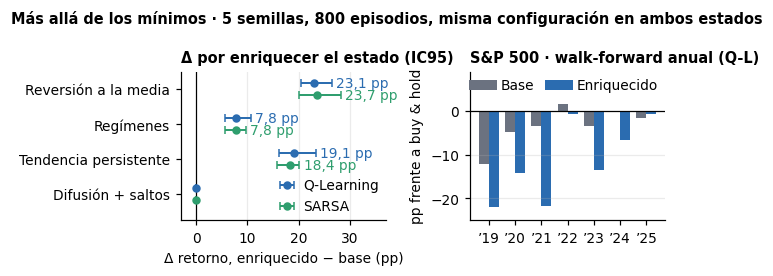

estado,Base,Enriquecido,Buy & hold
anio,,,
2019,+16.5 %,+6.6 %,+28.6 %
2020,+10.4 %,+1.0 %,+15.2 %
2021,+25.3 %,+7.0 %,+28.7 %
2022,-18.4 %,-20.7 %,-20.0 %
2023,+21.3 %,+11.0 %,+24.6 %
2024,+23.9 %,+17.4 %,+23.9 %
2025,+14.9 %,+15.8 %,+16.5 %


In [18]:
EXTRA_LABELS_INF = {"reversion_media": "Reversión a la media", "regimenes": "Regímenes",
                    "tendencia_persistente": "Tendencia persistente", "saltos": "Difusión + saltos"}
deltas_inf = load("03_estado_deltas")
anexo_inf = load("03_anexo")
controles_inf = load("03_anexo_controles")

wf = anexo_inf.query("experimento == 'walk_forward'").pivot(index="anio", columns="estado", values="retorno_mediana")
wf_bh = controles_inf.query("mercado == 'sp500_anual' and agente == 'buy_hold'").set_index("anio").retorno_mediana
wf["buy_hold"] = wf_bh
exceso_wf = (wf[["base", "enriquecido"]].sub(wf.buy_hold, axis=0) * 100)

with plt.rc_context(INFORME_RC):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(ANCHO_INFORME - 0.55, 2.5), gridspec_kw={"width_ratios": [1.05, 1]})
    orden = list(EXTRA_LABELS_INF)
    for j, (algoritmo, dy) in enumerate([("qlearning", 0.17), ("sarsa", -0.17)]):
        d = deltas_inf.query("algoritmo == @algoritmo").set_index("mercado").loc[orden]
        y = np.arange(len(orden))[::-1] + dy
        ax1.errorbar(100 * d.delta_mediana, y,
                     xerr=[100 * (d.delta_mediana - d.ic95_inf), 100 * (d.ic95_sup - d.delta_mediana)],
                     fmt="o", ms=4.5, color=AGENT_COLORS[algoritmo], capsize=2.5, lw=1.3,
                     label=AGENT_LABELS_INF[algoritmo])
        for yi, (m, fila) in zip(y, d.iterrows()):
            if fila.delta_mediana > 0:
                ax1.text(100 * fila.ic95_sup + 0.8, yi, f"{num_es(100 * fila.delta_mediana)} pp",
                         va="center", ha="left", color=AGENT_COLORS[algoritmo])
    ax1.axvline(0, color="black", lw=0.8)
    ax1.set_yticks(np.arange(len(orden))[::-1], [EXTRA_LABELS_INF[m] for m in orden])
    ax1.set_xlim(-3, 37)
    ax1.set_xlabel("Δ retorno, enriquecido − base (pp)")
    ax1.set_ylim(-0.75, len(orden) - 0.5)
    ax1.set_title("Δ por enriquecer el estado (IC95)", loc="left")
    ax1.legend(loc="lower right", handletextpad=0.2, borderaxespad=0.1)
    ax1.grid(axis="y", visible=False)

    anios = exceso_wf.index.to_numpy()
    w = 0.38
    ax2.bar(anios - w / 2, exceso_wf.base, w, color=GRIS_BASE, label="Base")
    ax2.bar(anios + w / 2, exceso_wf.enriquecido, w, color=AGENT_COLORS["qlearning"], label="Enriquecido")
    ax2.axhline(0, color="black", lw=0.8)
    ax2.set_xticks(anios, [f"’{a % 100:02d}" for a in anios])
    ax2.set_ylabel("pp frente a buy & hold")
    ax2.set_ylim(-25, 9)
    ax2.set_title("S&P 500 · walk-forward anual (Q-L)", loc="left")
    ax2.legend(loc="upper right", ncol=2, handletextpad=0.3, columnspacing=0.8, borderaxespad=0.1)
    ax2.grid(axis="x", visible=False)
    fig.suptitle("Más allá de los mínimos · 5 semillas, 800 episodios, misma configuración en ambos estados",
                 x=0.01, ha="left", fontsize=9.5, fontweight="bold")
    fig.tight_layout(w_pad=1.5)
    savefig(fig, "04_informe_mas_alla")
    plt.show()

(wf * 100).rename(columns={"base": "Base", "enriquecido": "Enriquecido", "buy_hold": "Buy & hold"}).style.format(
    "{:+.1f} %").set_caption("S&P 500 · retorno de cada año de test (mediana de 5 semillas)")

**Lectura.** En los sintéticos, el estado enriquecido mejora donde el mecanismo del mercado lo predice: reversión
(+23 pp), tendencia persistente (+18–19 pp) y regímenes (+8 pp, donde el estado base no operaba). En difusión + saltos
no cambia nada, porque los saltos no se pueden anticipar. En el S&P 500 no se traslada: el estado base hace como mucho
una operación y queda cerca de buy & hold, y el enriquecido queda por debajo todos los años.

**Pie para el informe:** *Figura 3. Izquierda: diferencia emparejada (mediana por historia) del retorno en test entre
el estado enriquecido y el base, con IC95 bootstrap condicional y sin corregir por comparaciones múltiples. Derecha:
S&P 500, retorno de cada año de test menos buy & hold; bins y entrenamiento solo con años anteriores.*

### 5.4 Tabla del informe

Una sola tabla con el mínimo que pide el enunciado: **rendimiento y convergencia** de los dos algoritmos y los dos
baselines en los cuatro mercados. Se añaden las operaciones (explican el 0 %) y el resultado del estado enriquecido del
03 como "más allá". Esa columna usa la configuración fija del 03 (800 episodios, sin ajustar), así que no es
comparable uno a uno con las columnas ajustadas.

In [19]:
POLITICA_INF = {
    "tendencia_ciclo": "Sigue la tendencia",
    "browniano": "No opera: no hay señal",
    "reversion_media": "Compra tras caídas y vende tras subidas",
    "regimenes": "No opera: el estado no ve el régimen",
}
conv_duelo = duelo_inf.groupby(["mercado", "agente"]).episodios_convergencia.median().unstack()

# Q-Learning con estado enriquecido y la configuración fija del 03 (D-1.2, D-1.4)
extras_inf = load("03_extras").set_index(["agente", "mercado"]).retorno_mediana
enriq_inf = {
    "tendencia_ciclo": anexo_inf.query("experimento == 'recompensa' and mercado == 'tendencia_ciclo' "
                                       "and recompensa == 'taller'").retorno_mediana.item(),
    "browniano": anexo_inf.query("experimento == 'placebo' and mercado == 'browniano' "
                                 "and estado == 'enriquecido'").retorno_mediana.item(),
    "reversion_media": extras_inf["qlearning_enriquecido", "reversion_media"],
    "regimenes": extras_inf["qlearning_enriquecido", "regimenes"],
}

tabla_inf = pd.DataFrame({
    "mercado": MARKETS_4,
    "aleatorio": final_ret.aleatorio.to_numpy(),
    "buy_hold": final_ret.buy_hold.to_numpy(),
    "qlearning": final_ret.qlearning.to_numpy(),
    "sarsa": final_ret.sarsa.to_numpy(),
    "ops_qlearning": final_ops.qlearning.to_numpy(),
    "ops_sarsa": final_ops.sarsa.to_numpy(),
    "conv_duelo_qlearning": [conv_duelo.loc[m, "qlearning"] if m in MERCADOS_OPERAN else np.nan for m in MARKETS_4],
    "conv_duelo_sarsa": [conv_duelo.loc[m, "sarsa"] if m in MERCADOS_OPERAN else np.nan for m in MARKETS_4],
    "qlearning_enriquecido_03": [enriq_inf[m] for m in MARKETS_4],
    "politica": [POLITICA_INF[m] for m in MARKETS_4],
})
tabla_inf.to_csv(RESULTS_DIR / "04_informe_tabla.csv", index=False)

tabla_md = pd.DataFrame({
    "Mercado": [MARKET_LABELS[m] for m in MARKETS_4],
    "Aleatorio": [ret_es(r, m) for r, m in zip(tabla_inf.aleatorio, MARKETS_4)],
    "Buy & hold": [ret_es(r, m) for r, m in zip(tabla_inf.buy_hold, MARKETS_4)],
    "**Q-Learning**": [f"**{ret_es(r, m)}**" for r, m in zip(tabla_inf.qlearning, MARKETS_4)],
    "**SARSA**": [f"**{ret_es(r, m)}**" for r, m in zip(tabla_inf.sarsa, MARKETS_4)],
    "Ops./ep. Q-L · SARSA": [f"{q:.0f} · {s:.0f}" for q, s in zip(tabla_inf.ops_qlearning, tabla_inf.ops_sarsa)],
    "Convergencia Q-L · SARSA (ep.)": ["—" if np.isnan(q) else f"{q:.0f} · {s:.0f}"
                                       for q, s in zip(tabla_inf.conv_duelo_qlearning, tabla_inf.conv_duelo_sarsa)],
    "Q-L enriquecido (03)": [ret_es(r, m) for r, m in zip(tabla_inf.qlearning_enriquecido_03, MARKETS_4)],
    "Política aprendida": tabla_inf.politica,
})
NOTA_TABLA = ("Mediana del retorno en 200 series de test; mercado 1 en múltiplo del capital. Q-Learning y SARSA: "
              "hiperparámetros elegidos en validación (D-0.4, D-2.3), mediana de 5 semillas. Convergencia: duelo a "
              "configuración idéntica, mediana de 3 semillas (D-2.5); en 2 y 4 no opera y la curva solo refleja que "
              "ε baja. Ops./ep.: política greedy en test con los hiperparámetros de cada algoritmo (en el duelo del mercado 1, con la "
              "misma configuración, SARSA opera menos). Q-L enriquecido: tendencia + MA30 + volatilidad (180 celdas), configuración fija del 03 "
              "(800 episodios, sin ajuste; D-1.2).")
texto_tabla = tabla_md.to_markdown(index=False, colalign=["left"] + ["right"] * 7 + ["left"]) + "\n\n" + NOTA_TABLA + "\n"
(RESULTS_DIR / "04_informe_tabla.md").write_text(texto_tabla, encoding="utf-8")
display(Markdown(texto_tabla))

| Mercado                  |   Aleatorio |   Buy & hold |   **Q-Learning** |   **SARSA** |   Ops./ep. Q-L · SARSA |   Convergencia Q-L · SARSA (ep.) |   Q-L enriquecido (03) | Política aprendida                      |
|:-------------------------|------------:|-------------:|-----------------:|------------:|-----------------------:|---------------------------------:|-----------------------:|:----------------------------------------|
| 1 · Tendencia + ciclo    |        x4,3 |        x33,6 |         **x502** |    **x472** |                48 · 57 |                        189 · 203 |                   x412 | Sigue la tendencia                      |
| 2 · Browniano geométrico |     −19,4 % |       −3,5 % |          **0 %** |     **0 %** |                  0 · 0 |                                — |                    0 % | No opera: no hay señal                  |
| 3 · Reversión a la media |     −17,2 % |       −0,3 % |      **+27,0 %** | **+27,0 %** |                29 · 29 |                        260 · 282 |                +42,8 % | Compra tras caídas y vende tras subidas |
| 4 · Regímenes            |     −22,0 % |      −12,5 % |          **0 %** |     **0 %** |                  0 · 0 |                                — |                 +7,8 % | No opera: el estado no ve el régimen    |

Mediana del retorno en 200 series de test; mercado 1 en múltiplo del capital. Q-Learning y SARSA: hiperparámetros elegidos en validación (D-0.4, D-2.3), mediana de 5 semillas. Convergencia: duelo a configuración idéntica, mediana de 3 semillas (D-2.5); en 2 y 4 no opera y la curva solo refleja que ε baja. Ops./ep.: política greedy en test con los hiperparámetros de cada algoritmo (en el duelo del mercado 1, con la misma configuración, SARSA opera menos). Q-L enriquecido: tendencia + MA30 + volatilidad (180 celdas), configuración fija del 03 (800 episodios, sin ajuste; D-1.2).


## 6. Análisis crítico

### 6.1 Por qué el diseño es así

- **Mediana como métrica principal (D-0.3).** En el mercado 1 el retorno compuesto con un 10 % de ruido por paso tiene
  colas enormes: la media de buy & hold es +19 925 % y la mediana +3 262 %, y la desviación típica de Q-Learning es el
  doble de su media. La media ± std se guarda al lado, pero no sirve para comparar.
- **Bins por cuantiles, 10 por variable (D-1.1).** Con bordes fijos, el mercado 1 cae casi siempre en los bins extremos
  (00 §4). Con cuantiles de train cada bin recibe ≈ 10 % de los pasos y la misma regla vale para el S&P 500. Con 20
  celdas, cada una se visita ≈ 19 400 veces (mediana) en 800 episodios (`03_cobertura.csv`).
- **α pequeño (D-2.2).** La ventaja por paso (≈ 0,1 %) es menor que el ruido que mete en Q un α grande. En validación,
  el mercado 1 da x527 con α = 0,001 y x14 con α = 0,1, y en reversión Q-Learning deja de operar con α ≥ 0,03.
- **Validación separada del test (D-0.4).** Elegir entre 160 configuraciones es optimista: en reversión, la elegida da
  +34,0 % en validación y +27,0 % en test. El test se usó una sola vez.
- **Semillas y parsimonia (D-2.3).** 3 semillas por configuración y 5 en el resultado final. Entre α = 0,0005 y 0,01
  el mercado 1 forma una meseta (x527 con tres de esos valores), y sin la regla de parsimonia se habría elegido por
  ruido. Las 5 semillas finales se ven en la figura 1: Q-Learning va de x472 a x605 en el mercado 1.
- **Duelo a configuración idéntica (D-2.5).** La convergencia del resultado final mezcla algoritmo e hiperparámetros;
  el duelo los separa.
- **Controles del 03 (D-1.2, D-1.4).** Base y enriquecido con el mismo presupuesto e historias, diferencias
  emparejadas, placebos y un factor cada vez. Así la mejora se puede atribuir al estado y no al ajuste.

### 6.2 Limitaciones

- **El estado no es markoviano (§2.2 del enunciado).** Seis precios no identifican el régimen ni la distancia a la
  media. Con la misma configuración del 03, añadir MA30 y volatilidad lleva reversión de +18,1 % a +42,8 % y regímenes
  de 0 % a +7,8 %. Pero 180 celdas tampoco garantizan un estado markoviano, y cada celda se visita unas 13 veces menos
  (1 470 frente a 19 390 en regímenes).
- **La recompensa suma y el balance compone.** Con γ < 1 se maximiza además una suma descontada, no el capital final.
  En la práctica pesa poco: con recompensa log(balance), el mercado 1 pasa de x412 a x431, dentro del rango entre
  semillas, y en el resto cambia menos de 3 pp (03 §9.6).
- **El final del episodio es un límite de tiempo, no un estado terminal (D-2.1).** Afecta a 1 de 494 decisiones.
- **"Q-Learning converge antes" es una afirmación débil.** Se basa en 3 semillas y en un criterio descriptivo de la
  curva online, que también recoge el descenso de ε. En el mercado 1 Q-Learning solo gana en 1 de 3 semillas.
- **Un único recorrido real (D-0.5).** En 2024–2025 el estado base gana a buy & hold (+45,9 % frente a +44,2 %) con
  una sola operación: es el momento de entrada, no una estrategia. En el walk-forward, el base solo bate a buy & hold
  en 2022 y el enriquecido no lo bate ningún año. Con los retornos barajados, el enriquecido se queda en +11,1 %
  frente a +44,2 %: no aparece una ventaja falsa.
- **Sin dividendos, spread, deslizamiento ni intereses del efectivo.** La comisión es la única fricción. Al subirla al
  0,5 %, reversión aguanta (+23,0 % con 6 operaciones) pero la ventaja en regímenes desaparece ya con 0,25 %.
- **Comparaciones múltiples.** 480 entrenamientos en los barridos del 01–02 y 360 en el anexo, con IC bootstrap sin
  corregir. Además, los indicadores se eligieron conociendo cómo se generan los mercados sintéticos.

### 6.3 Con más tiempo

- **Estado:** elegir los indicadores en validación y probar aproximación de funciones (*tile coding* o lineal) para
  no diluir las visitas en 180 celdas.
- **Generalización:** entrenar con una mezcla de generadores, que es el "reto mayor" que propuso el profesor, y evaluar en
  todos.
- **Convergencia:** 10–20 semillas en el duelo y medirla sobre la política greedy en validación, no sobre la recompensa
  online.
- **Realismo:** índice con dividendos, spread, varios activos y posiciones parciales en lugar de todo o nada.
- **Estadística:** corregir por comparaciones múltiples (Holm) y fijar las hipótesis antes de mirar el test.

In [20]:
# Comprobación: cada cifra del §5–§6 sale de los CSV
def pp(r):
    return round(100 * r, 1)

bh1 = baselines_inf.query("agente == 'buy_hold' and mercado == 'tendencia_ciclo'").iloc[0]
q1 = finales_inf.query("agente == 'qlearning' and mercado == 'tendencia_ciclo'").iloc[0]
assert (round(100 * bh1.retorno_medio), round(100 * bh1.retorno_mediana)) == (19925, 3262)
assert 1.9 < q1["std"] / q1.retorno_medio < 2.1                                         # "el doble"
cob = load("03_cobertura").set_index(["mercado", "estado"]).visitas_mediana
assert round(cob["regimenes", "base"], -2) == 19400 and cob["regimenes", "enriquecido"] == 1470
assert round(cob["regimenes", "base"] / cob["regimenes", "enriquecido"]) == 13
ga = load("01_grid_alpha").groupby(["mercado", "alpha"]).retorno_mediana.median()
assert round(1 + ga["tendencia_ciclo", 0.001]) == 527 and round(1 + ga["tendencia_ciclo", 0.1]) == 14
assert all(ga["tendencia_ciclo", a] == ga["tendencia_ciclo", 0.001] for a in (0.0005, 0.01))
assert ga["reversion_media", 0.03] == 0 and ga["reversion_media", 0.1] == 0
grids = [load(f"{n}_grid_{e}") for n in ("01", "02") for e in ("alpha", "gamma", "epsilon", "episodios")]
assert sum(map(len, grids)) == 480 and sum(map(len, grids)) / 3 == 160
ge = load("01_grid_episodios").query("mercado == 'reversion_media' and n_episodes == 500").retorno_mediana.median()
assert pp(ge) == 34.0 and pp(final_ret.loc["reversion_media", "qlearning"]) == 27.0
assert round(1 + rango_semillas.loc[("tendencia_ciclo", "qlearning"), "min"]) == 472
assert round(1 + rango_semillas.loc[("tendencia_ciclo", "qlearning"), "max"]) == 605
dmed = duelo_inf.groupby(["mercado", "agente"]).episodios_convergencia.median()
assert (dmed["tendencia_ciclo"].tolist(), dmed["reversion_media"].tolist()) == ([189, 203], [260, 282])
assert conv_pares.loc["tendencia_ciclo", "Q-L antes"].sum() == 1 and conv_pares.loc["reversion_media", "Q-L antes"].all()
assert (conv_pares.loc["tendencia_ciclo"].pipe(lambda d: (d.sarsa - d.qlearning).abs()).sort_values().tolist()[:2] == [1, 1])
assert pp(extras_inf["qlearning_base", "reversion_media"]) == 18.1 and pp(extras_inf["qlearning_enriquecido", "reversion_media"]) == 42.8
assert extras_inf["qlearning_base", "regimenes"] == 0 and pp(extras_inf["qlearning_enriquecido", "regimenes"]) == 7.8
rec = anexo_inf.query("experimento == 'recompensa'").set_index(["mercado", "recompensa"]).retorno_mediana
assert (round(1 + rec["tendencia_ciclo", "taller"]), round(1 + rec["tendencia_ciclo", "log"])) == (412, 431)
rs = anexo_inf.query("experimento == 'recompensa' and mercado == 'tendencia_ciclo'").set_index("recompensa")
assert rs.loc["taller", "minimo_semilla"] < rs.loc["log", "retorno_mediana"] < rs.loc["taller", "maximo_semilla"]
assert ((rec.xs("log", level=1) - rec.xs("taller", level=1)).drop("tendencia_ciclo").abs() < 0.03).all()
dlt = deltas_inf.set_index(["mercado", "algoritmo"]).delta_mediana
assert [round(pp(dlt["reversion_media", a])) for a in ("qlearning", "sarsa")] == [23, 24]
assert sorted(round(pp(dlt["tendencia_persistente", a])) for a in ("qlearning", "sarsa")) == [18, 19]
assert [pp(dlt["regimenes", a]) for a in ("qlearning", "sarsa")] == [7.8, 7.8] and (dlt["saltos"] == 0).all()
sp = extras_inf.xs("sp500_real", level=1)
assert (pp(sp["qlearning_base"]), pp(sp["buy_hold"])) == (45.9, 44.2)
assert load("03_extras").query("agente == 'qlearning_base' and mercado == 'sp500_real'").n_trades.item() == 1
assert exceso_wf.index[exceso_wf.base > 0].tolist() == [2022] and (exceso_wf.enriquecido < 0).all()
plc = anexo_inf.query("experimento == 'placebo' and mercado == 'sp500_barajado'").set_index("estado").retorno_mediana
assert pp(plc["enriquecido"]) == 11.1 and pp(controles_inf.query("mercado == 'sp500_barajado' and agente == 'buy_hold'").retorno_mediana.item()) == 44.2
com = anexo_inf.query("experimento == 'comision'").set_index(["mercado", "coste"])
assert pp(com.loc[("reversion_media", 0.005), "retorno_mediana"]) == 23.0 and round(com.loc[("reversion_media", 0.005), "n_trades"]) == 6
assert com.loc[("regimenes", 0.0025), "retorno_mediana"] == 0 and com.loc[("regimenes", 0.001), "retorno_mediana"] > 0
assert len(load("03_anexo_semillas").drop_duplicates("id")) == 360
print("Todas las cifras del §5–§6 coinciden con los CSV.")

Todas las cifras del §5–§6 coinciden con los CSV.
